# Práctica de detección de objetos

### **Grupo:** N — **Integrantes:** Lucas Amado Oseira y María Lestón Geada
##### **Dataset:** Lettuce Pallets (`Francesco/lettuce-pallets`)
##### **Detectores:** Cascade R-CNN (Detectron2) y SSD300-VGG16 (Torchvision), ambos preentrenados en MS COCO

## 0. Cómo usar este cuaderno y resumen de decisiones

El cuaderno está pensado para ejecutarse de arriba abajo en Kaggle. Primero se instalan las dependencias y se configura el entorno. A continuación, se cargan y limpian los datos, se analiza el dataset y se define la infraestructura común de evaluación. Por último, se entrena y evalúa el baseline de cada detector (SSD300 y Cascade R-CNN) y se comparan en una misma sección de resultados.
El flujo de trabajo quedaría así:

1. Instalar dependencias → 2. Configurar → 3. Cargar y limpiar los datos → 4. Analizar el dataset → 5. Infraestructura común → 6. Baseline SSD300 → 7. Baseline Cascade R-CNN → 8. Resultados

Todo lo que se genera se guarda en `/kaggle/working/work` (checkpoints, predicciones, figuras y `results.csv`). Si un entrenamiento ya existe en esa carpeta se reutiliza y solo se recalcula la evaluación. Los resultados de todos los experimentos se acumulan en `results.csv`.

#### **Resumen de decisiones:**
Las decisiones de diseño más importantes son las siguientes:

| Decisión | Elección | Motivo |
|---|---|---|
| Clases | Se elimina `lettuce` (id 0) → 5 clases | Es la categoría "padre" de Roboflow, no tiene ninguna anotación y obligaría a los modelos a trabajar con 6 clases cuando el guion habla de 5. |
| Protocolo | Entrenar en *train*, tomar decisiones en *val* y reportar cifra de *test* | Evita sobreajustar las decisiones al test |
| Baseline | Fine-tuning de pesos COCO, sin aumento de datos y uso de una única LR por detector | Punto de partida limpio |
| Evaluación | Mismo código (`evaluate_coco`), umbrales, protocolo de medida de tiempos y formato de impresión de resultados para ambos detectores | Comparación justa SSD vs Cascade |

## 1. Imports y configuración del entorno

Ejecutamos esta celda una vez por sesión de Kaggle. Detectron2 se compila desde el repositorio oficial. Si la sesión pide reiniciar el kernel, lo reiniciamos y continuamos desde la celda de imports.

In [ ]:
# Detectron2 se compila desde el repositorio y se omite si ya está instalado
!python -c "import detectron2" 2>/dev/null || pip -q install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

Importamos las librerías necesarias para realizar la práctica.

In [6]:
import os, sys, io, json, time, math, copy, random, tarfile, contextlib, gc, importlib.util
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from datasets import load_dataset

import torch
import torchvision
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Importamos las librerías de pycocotools para la evaluación del modelo y el manejo del dataset COCO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Importamos las librerías de Detectron2 para la configuración, entrenamiento y evaluación del modelo
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.evaluation import COCOEvaluator
from detectron2.data import (DatasetCatalog, MetadataCatalog, DatasetMapper,
                                build_detection_train_loader, transforms as T)
from detectron2.data.datasets import register_coco_instances

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


La práctica se ejecuta en Kaggle. Definimos las constantes: rutas de trabajo (`/kaggle/working`), el origen del dataset y los parámetros de inferencia comunes a ambos detectores.
Además, fijaremos una semilla que nos garantice la reproducibilidad de los resultados.

Para obtener el origen del dataset se prueba en este orden:
1. datos ya preparados en `data/raw`
2. carpetas Roboflow (`train/`, `valid/`, `test/`) o un `dataset.tar.gz` añadidos como Input del notebook
3. descarga desde Hugging Face (`Francesco/lettuce-pallets`) y exportación al mismo formato Roboflow, de modo que la limpieza posterior es idéntica en los tres casos.

In [ ]:
SEED = 2710
DATASET_NAME = "lettuce-pallets"
HF_DATASET = "Francesco/lettuce-pallets" # solo se usa si no hay dataset en el input de kaggle

IN_KAGGLE = Path("/kaggle/working").exists()
KAGGLE_INPUT = Path("/kaggle/input")
ROOT_DIR = Path("/kaggle/working") if IN_KAGGLE else Path(".") # usamos el directorio actual en local
WORK_DIR = ROOT_DIR / "work" # checkpoints, predicciones, figuras y results.csv
DATA_DIR = ROOT_DIR / "data" # datos extraídos y limpios

PRETRAINED = True # pesos preentrenados en COCO

# Parámetros de inferencia comunes a ambos detectores
SCORE_THRESH_EVAL = 0.001 # umbral de confianza para filtrar predicciones durante la evaluación
NMS_IOU = 0.5 # umbral de IoU para la supresión de no-máximos durante la evaluación
MAX_DETS = 25 # número máximo de predicciones por imagen durante la evaluación

SPLITS = ("train", "val", "test")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| Kaggle:", IN_KAGGLE)

Device: cuda | Kaggle: True


In [8]:
# Fijamos todas las semillas para asegurar la reproducibilidad de los experimentos
def seed_everything(seed=SEED, deterministic=True):
    """Fija todas las semillas. 'deterministic' hace cuDNN determinista (algo más lento)."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Función para fijar la semilla de los workers del DataLoader, si no el aumento de datos no es reproducible
def seed_worker(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

# Creamos un generador de números aleatorios para el DataLoader, que se utilizará para inicializar los workers y garantizar la reproducibilidad
def make_generator(seed=SEED):
    return torch.Generator().manual_seed(seed)

seed_everything() # Fijamos la semilla

# Creamos los subdirectorios necesarios para almacenar los resultados del entrenamiento y la evaluación
for sub in ("ckpt", "preds", "figs", "d2"):
    (WORK_DIR / sub).mkdir(parents=True, exist_ok=True)

# Creamos los subdirectorios necesarios para almacenar los datos limpios y procesados del dataset
DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR = DATA_DIR / "clean" # directorio para almacenar los datos limpios y procesados del dataset
CLEAN_DIR.mkdir(exist_ok=True)
print("WORK_DIR:", WORK_DIR.resolve())

WORK_DIR: /kaggle/working/work


## 2. Datos: extracción, limpieza y formato unificado

Comenzaremos a tratar los datos: localizamos el dataset, el JSON y la carpeta de imágenes de cada split. También localizamos los splits por el nombre exacto de la carpeta (`train`, `valid`, `test`) de forma robusta.

Con la función `export_hf` descargamos el dataset de Hugging Face mediante `load_dataset` y lo escribimos en disco con el mismo formato que Roboflow, de modo que el resto del cuaderno funcione igual con independencia del origen de los datos.

Los nombres de los splits se normalizan con el diccionario `SPLIT_DIR_ALIASES` (por ejemplo, `validation` pasa a `valid`). Cada imagen se guarda como `00000.jpg`, `00001.jpg`... y su identificador es simplemente su índice `id` dentro del split; así, los nombres de archivo y los ids son únicos y no dependemos del campo `image_id` (índice de la imagen) del dataset original, que podía repetirse entre splits.

Las anotaciones se guardan en formato COCO, con `bbox = [x, y, w, h]` (x, y: esquina superior izquerda, w: ancho, h: alto). Guardamos también el área (`w·h`), que COCO usa para clasificar los objetos en pequeños, medianos y grandes durante la evaluación, e `iscrowd = 0`, porque cada anotación es un objeto individual y no una multitud:

```python
{"id": n, "image_id": idx, "category_id": int(cat), "bbox": [x, y, w, h], "area": w*h, "iscrowd": 0}
```

`category_id` se corresponde con ClassLabel. En esta fase conservamos todas las categorías originales, incluida `lettuce` con id 0. Se eliminará más adelante, durante la limpieza.

In [ ]:
SPLIT_DIR_ALIASES = {"train": "train", "valid": "val", "validation": "val", "val": "val", "test": "test"}

# Extraemos el tar.gz si el destino está vacío
def extract_tar(tar_path, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    if not any(dest.iterdir()):
        with tarfile.open(tar_path, "r:*") as tar:
            try: tar.extractall(dest, filter="data")
            except TypeError: tar.extractall(dest)
    return dest

# Localizamos los splits de entrenamiento, validación y test en el dataset extraído
def locate_raw_splits(root):
    raw = {}
    for js in Path(root).rglob("*.json"):
        key = SPLIT_DIR_ALIASES.get(js.parent.name.lower())
        if key and key not in raw:
            raw[key] = {"json": js, "images": js.parent} # en Roboflow, las imágenes están junto al JSON
    missing = [s for s in SPLITS if s not in raw]
    assert not missing, f"Faltan splits: {missing}"
    return raw

def find_tar_in_input():
    if not KAGGLE_INPUT.exists(): return None
    for pat in ("*.tar.gz", "*.tgz", "*.tar"):
        found = sorted(KAGGLE_INPUT.rglob(pat))
        if found: return found[0]
    return None

def export_hf(dest):
    # Descargamos en memoria el dataset de Hugging Face y lo escribimos en el directorio de destino como Roboflow: <split>/{imágenes, _annotations.coco.json}.
    hf_ds = load_dataset(HF_DATASET)
    # Mapeamos los nombres internos de los splits con  los nombres de directorio que queremos usar en el destino
    dir_names = {"train": "train", "val": "valid", "test": "test"}
    # Accedemos al primer split disponible e inspeccionamos el esquema (features) de categoría de objects para tener los nombres de las clases
    feat = hf_ds[next(iter(hf_ds.keys()))].features["objects"]["category"]
    # En caso de que la columna de categorías esté en un un contenedor de tipo Sequence/List, obtenemos el feature ClassLabel subyacente
    feat = getattr(feat, "feature", feat) # Sequence/List(ClassLabel) -> ClassLabel
    # Si el feature es de tipo ClassLabel, obtenemos los nombres de las clases, si no, dejamos names como None
    names = list(feat.names) if getattr(feat, "names", None) else None
    # Inicializamos un conjunto para almacenar las categorías observadas en el dataset
    observed = set()

    # Recorremos cada split del dataset
    for split_name, ds in hf_ds.items():
        # Normalizamos el nombre del split a minúsculas y determinamos la clave correspondiente en dir_names
        s = split_name.lower()
        key = "train" if s == "train" else "val" if "val" in s else "test" if "test" in s else None
        if key is None: continue
        out = Path(dest) / dir_names[key]
        out.mkdir(parents=True, exist_ok=True)
        # Inicializamos listas para almacenar la información de las imágenes y anotaciones
        images, anns = [], []
        # Iteramos sobre cada fila del split del dataset convirtiendo las imágenes a RGB y guardándolas en el directorio correspondiente, mientras recopilamos la información de las anotaciones
        for idx, row in enumerate(ds):
            img = row["image"].convert("RGB")
            fn = f"{idx:05d}.jpg"; img.save(out / fn, quality=95)
            images.append({"id": idx, "file_name": fn, "width": img.width, "height": img.height})
            objs = row["objects"]
            # Emparejamos cada bounding box con su categoría correspondiente y agregamos la información a la lista de anotaciones, mientras registramos las categorías observadas
            for bbox, cat in zip(objs["bbox"], objs["category"]):
                x, y, w, h = map(float, bbox); observed.add(int(cat))
                anns.append({"id": len(anns) + 1, "image_id": idx, "category_id": int(cat),
                             "bbox": [x, y, w, h], "area": w * h, "iscrowd": 0})
        # Escribimos el archivo _annotations.coco.json para el split actual, incluyendo las imágenes y anotaciones recopiladas
        (out / "_annotations.coco.json").write_text(json.dumps({"images": images, "annotations": anns, "categories": []}))
    # Actualizamos el archivo _annotations.coco.json para cada split, incluyendo las categorías
    cat_ids = range(len(names)) if names else sorted(observed)
    cats = [{"id": i, "name": names[i] if names else str(i)} for i in cat_ids]
    for d in dir_names.values():
        p = Path(dest) / d / "_annotations.coco.json"
        j = json.loads(p.read_text()); j["categories"] = cats; p.write_text(json.dumps(j))
    return dest

raw_root = DATA_DIR / "raw"
if not raw_root.exists() or not any(raw_root.iterdir()):
    print("Preparando datos RAW...")
    RAW = locate_raw_splits(export_hf(raw_root))
for s in SPLITS: print(f"{s}: {RAW[s]['json']}")

Preparando datos RAW...


train: /kaggle/working/data/raw/train/_annotations.coco.json
val: /kaggle/working/data/raw/valid/_annotations.coco.json
test: /kaggle/working/data/raw/test/_annotations.coco.json


A continuación, cargamos el dataset de entrenamiento COCO y mostramos información sobre las distintas categorías de lechuga y las anotaciones existentes para cada imagen.

In [10]:
# Información del dataset ANTES de la limpieza (lee el JSON original de Roboflow)
raw_train = COCO(str(RAW["train"]["json"]))
raw_cats = sorted(raw_train.loadCats(raw_train.getCatIds()), key=lambda x: x["id"])

print("\nCategorías COCO (originales):", [(c["id"], c["name"]) for c in raw_cats])
print(f"Total imágenes de entrenamiento: {len(raw_train.getImgIds())}")
print(f"Número de anotaciones train: {len(raw_train.getAnnIds())}")

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!

Categorías COCO (originales): [(0, 'lettuce'), (1, 'Ready'), (2, 'empty_pod'), (3, 'germination'), (4, 'pod'), (5, 'young')]
Total imágenes de entrenamiento: 1060
Número de anotaciones train: 13812


En principio vemos que existen 6 categorías distintas: *'lettuce', 'Ready', 'empty_pod', 'germination', 'pod'* y *'young'*, repartidas entre 1060 imágenes de entrenamiento y con un total de 13812 anotaciones.

Mostramos las anotaciones por categoría.

In [11]:
for c in raw_cats:
    n = len(raw_train.getAnnIds(catIds=[c["id"]]))
    print(f"  id {c['id']}: {c['name']:11s} -> {n} anotaciones")

  id 0: lettuce     -> 0 anotaciones
  id 1: Ready       -> 1387 anotaciones
  id 2: empty_pod   -> 1100 anotaciones
  id 3: germination -> 4651 anotaciones
  id 4: pod         -> 2531 anotaciones
  id 5: young       -> 4143 anotaciones


Comprobamos que todas las categorías tienen anotaciones menos `lettuce`.

### Limpieza de las anotaciones

A partir del análisis anterior generamos un JSON limpio por split aplicando cuatro decisiones.

La primera es eliminar la categoría `lettuce` (id 0). En Roboflow actúa como categoría *"padre"* de las demás y no tiene anotaciones propias, de modo que mantenerla habría añadido una clase fantasma que nunca aparece y habría dejado a los modelos con 6 clases en lugar de las 5 reales.

La segunda es renumerar las clases de 1 a 5: en torchvision la etiqueta 0 está reservada al fondo, y con identificadores contiguos desde 1 la etiqueta del modelo coincide directamente con el `category_id`, así que no hace falta ninguna conversión ni hay riesgo de desplazar las clases al evaluar.

La tercera decisión es recortar las cajas a los límites de la imagen y descartar las degeneradas, es decir, las de ancho o alto menor de 1 px, porque una caja de tamaño nulo provoca errores y pérdidas `NaN` durante el entrenamiento. Esto afecta a una única anotación de *test* y a ninguna de *train* ni *val*.

Por último, conservamos en el JSON las imágenes sin objetos, que se utilizan en la evaluación, donde cualquier detección sobre ellas cuenta como falso positivo, aunque Detectron2 las ignora al entrenar.

In [12]:
def build_clean_coco(raw, out_dir):
    """Genera un JSON COCO limpio por split. Devuelve (CLEAN, class_names, class_ids)."""
    # Creamos el directorio de salida si no existe
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Leemos el JSON de entrenamiento original y obtenemos los nombres de las categorías y los IDs utilizados
    train = json.loads(Path(raw["train"]["json"]).read_text())
    old_names = {c["id"]: c["name"] for c in train["categories"]}
    used_ids = sorted({a["category_id"] for a in train["annotations"]})
    dropped = [n for i, n in old_names.items() if i not in used_ids] # categorías descartadas
    print("Categorías descartadas (sin anotaciones en train):", dropped)

    # Creamos un diccionario que mapea los nombres de las categorías a nuevos IDs consecutivos (1..K) para las categorías utilizadas
    name2new = {old_names[i]: n + 1 for n, i in enumerate(used_ids)}

    # Iteramos sobre cada split y generamos un nuevo JSON COCO limpio
    # Descartamos anotaciones de categorías no utilizadas y cajas degeneradas
    clean = {}
    for split in SPLITS:
        d = json.loads(Path(raw[split]["json"]).read_text())
        id2name = {c["id"]: c["name"] for c in d["categories"]}
        imgs = {im["id"]: im for im in d["images"]}
        new_anns, stats = [], Counter()
        
        for a in d["annotations"]:
            name = id2name.get(a["category_id"])
            
            # Descartamos cajas degeneradas (cajas con ancho o alto menor que 1 píxel)
            im = imgs[a["image_id"]]; x, y, w, h = a["bbox"]
            x1, y1 = max(0.0, x), max(0.0, y)
            x2, y2 = min(float(im["width"]), x + w), min(float(im["height"]), y + h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                stats["caja_degenerada"] += 1
                continue
            
            # Creamos la nueva anotación con el nuevo ID de categoría y la caja ajustada
            new_anns.append({"id": len(new_anns) + 1, "image_id": a["image_id"],
                             "category_id": name2new[name], "bbox": [x1, y1, x2 - x1, y2 - y1],
                             "area": (x2 - x1) * (y2 - y1), "iscrowd": 0})
        
        # Guardamos el nuevo JSON COCO limpio para el split actual
        out = {"images": d["images"], "annotations": new_anns,
               "categories": [{"id": i, "name": n} for n, i in name2new.items()]}
        
        # Guardamos el JSON limpio en el directorio de salida y almacenamos la información del split en el diccionario 'clean'
        p = out_dir / f"{split}_clean.json"; p.write_text(json.dumps(out))
        clean[split] = {"json": p, "images": Path(raw[split]["images"])}
        print(f"{split:5s}: {len(d['images'])} imgs | {len(d['annotations'])} -> {len(new_anns)} anotaciones | descartes: {dict(stats)}")
    names = list(name2new.keys())
    ids = list(name2new.values())
    return clean, names, ids

CLEAN, CLASS_NAMES, CLASS_IDS = build_clean_coco(RAW, CLEAN_DIR)
K = len(CLASS_NAMES) # nº de clases reales
# Creamos un diccionario que mapea los IDs de las clases a sus índices
CID2IDX = {c: i for i, c in enumerate(CLASS_IDS)}
print(f"\nK = {K} clases:", dict(zip(CLASS_IDS, CLASS_NAMES)))

# Creamos un diccionario que mapea los splits a sus objetos COCO correspondientes para facilitar la evaluación
COCO_GT = {s: COCO(str(CLEAN[s]["json"])) for s in SPLITS}

Categorías descartadas (sin anotaciones en train): ['lettuce']
train: 1060 imgs | 13812 -> 13812 anotaciones | descartes: {}
val  : 151 imgs | 2042 -> 2042 anotaciones | descartes: {}
test : 299 imgs | 3867 -> 3866 anotaciones | descartes: {'caja_degenerada': 1}

K = 5 clases: {1: 'Ready', 2: 'empty_pod', 3: 'germination', 4: 'pod', 5: 'young'}
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


## 3. Análisis exploratorio del dataset

Antes de proponer ninguna mejora vamos a medir las características del dataset que más condicionan el diseño del experimento: el reparto de clases, el número de objetos por imagen y, sobre todo, el tamaño de los objetos.

El reparto de clases nos dice si hay categorías raras que justifiquen un muestreo balanceado o una pérdida ponderada. El tamaño de los objetos es especialmente relevante para SSD300, que reescala todas las imágenes a 300×300 píxeles y pierde por tanto detalle en los objetos pequeños, así que calcularemos también el tamaño efectivo de cada objeto tras ese reescalado. Por último, realizaremos una revisión de algunas imágenes con sus anotaciones para identificar a simple vista los retos visuales (iluminación, oclusiones, parecido entre clases), que son los que deben orientar las estrategias de mejora, incluido qué tipo de aumento de datos tiene sentido aplicar.

In [ ]:
# Creamos un DataFrame con las anotaciones de todos los splits
# Incluimos información sobre el tamaño y la relación de aspecto de cada objeto
def annotations_dataframe(coco, split):
    rows = []
    for a in coco.anns.values():
        im = coco.imgs[a["image_id"]]

        # Calculamos el área de la caja delimitadora
        x, y, w, h = a["bbox"]
        area = w * h

        # Agregamos la información al DataFrame
        rows.append({"split": split, "image_id": a["image_id"],
                     "cls": CLASS_NAMES[CID2IDX[a["category_id"]]], # nombre de la clase
                     "w": w, "h": h, "area": area, # área de la caja delimitadora
                     "sqrt_area": math.sqrt(area), # raíz cuadrada del área de la caja delimitadora
                     "rel_size": math.sqrt(area / (im["width"] * im["height"])), # tamaño relativo del objeto respecto al tamaño de la imagen
                     "aspect": w / h}) # relación entre el ancho y el alto de la caja delimitadora
    df = pd.DataFrame(rows)
    # Clasificamos los objetos en categorías de tamaño: pequeño, mediano y grande según el área de la caja delimitadora
    # Los límites de las categorías se establecen en 32^2 y 96^2 píxeles cuadrados, según la convención de COCO
    df["size_cat"] = pd.cut(df["area"], [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
    return df

# Creamos el DataFrame con las anotaciones para todos los splits
ANN_DF = pd.concat([annotations_dataframe(COCO_GT[s], s) for s in SPLITS], ignore_index=True)

# Mostramos un resumen de las imágenes y anotaciones por split
print("Imágenes y anotaciones por split:")
summary = []
for s in SPLITS:
    c = COCO_GT[s]
    per_img = Counter(a["image_id"] for a in c.anns.values()) # contamos el número de anotaciones por imagen
    n_img = len(c.imgs)
    n_empty = sum(1 for i in c.imgs if per_img.get(i, 0) == 0) # contamos el número de imágenes sin anotaciones
    summary.append({"split": s, "imágenes": n_img, "anotaciones": len(c.anns), "imgs_sin_objetos": n_empty,
                    "objs/img media": round(len(c.anns) / n_img, 1), # número medio de objetos por imagen
                    "objs/img máx": max(per_img.values())}) # número máximo de objetos en una imagen
display(pd.DataFrame(summary).set_index("split"))

# Mostramos un resumen de las anotaciones por clase y split
print("\nAnotaciones por clase y split:")
class_counts = ANN_DF.pivot_table(index="cls", columns="split", values="area", aggfunc="count").reindex(CLASS_NAMES)[list(SPLITS)]
class_counts["% train"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(1)
display(class_counts)

# Mostramos un resumen de la resolución de las imágenes en el dataset
print("\nResolución de las imágenes:")
display(pd.Series([(im["width"], im["height"]) for c in COCO_GT.values() for im in c.imgs.values()]).value_counts().head())

# SSD300 redimensiona todas las imágenes a 300x300
# Calculamos el tamaño efectivo del objeto en píxeles tras el reescalado a 300x300 píxeles
ANN_DF["px_ssd300"] = ANN_DF["rel_size"] * 300
tr = ANN_DF[ANN_DF.split == "train"]

# Mostramos un resumen de la distribución del tamaño de los objetos en el conjunto de entrenamiento
print("\nTamaño de objeto (train):", tr["size_cat"].value_counts(normalize=True).round(3).to_dict())

# Mostramos un resumen de la raíz cuadrada del área de los objetos en píxeles originales y sus cuantiles
print("sqrt(área) px originales, cuantiles:", tr["sqrt_area"].quantile([.05, .25, .5, .75, .95]).round(1).to_dict())

# Mostramos un resumen del porcentaje de objetos con tamaño efectivo menor a 16 píxeles en SSD300
# Los objetos muy pequeños pueden ser difíciles de detectar para el modelo SSD300
# Este porcentaje nos da una idea de cuántos objetos podrían ser problemáticos en términos de detección
print(f"% objetos con tamaño efectivo < 16 px en SSD300: {100*(tr['px_ssd300'] < 16).mean():.3f}%")

Imágenes y anotaciones por split:


,imágenes,anotaciones,imgs_sin_objetos,objs/img media,objs/img máx
split,,,,,
train,1060,13812,8,13.0,20
val,151,2042,1,13.5,21
test,299,3866,0,12.9,20



Anotaciones por clase y split:


split,train,val,test,% train
cls,,,,
Ready,1387,246,376,10.0
empty_pod,1100,182,311,8.0
germination,4651,631,1321,33.7
pod,2531,337,725,18.3
young,4143,646,1133,30.0



Resolución de las imágenes:


(640, 640)    1510
Name: count, dtype: int64


Tamaño de objeto (train): {'medium': 0.632, 'large': 0.368, 'small': 0.0}
sqrt(área) px originales, cuantiles: {0.05: 49.1, 0.25: 62.5, 0.5: 80.9, 0.75: 122.0, 0.95: 220.0}
% objetos con tamaño efectivo < 16 px en SSD300: 0.0%


Mostramos además un resumen gráfico de las anotaciones por clase, el número de objetos por imagen, la distribución del tamaño de los objetos y la relación de aspecto de las cajas delimitadoras.

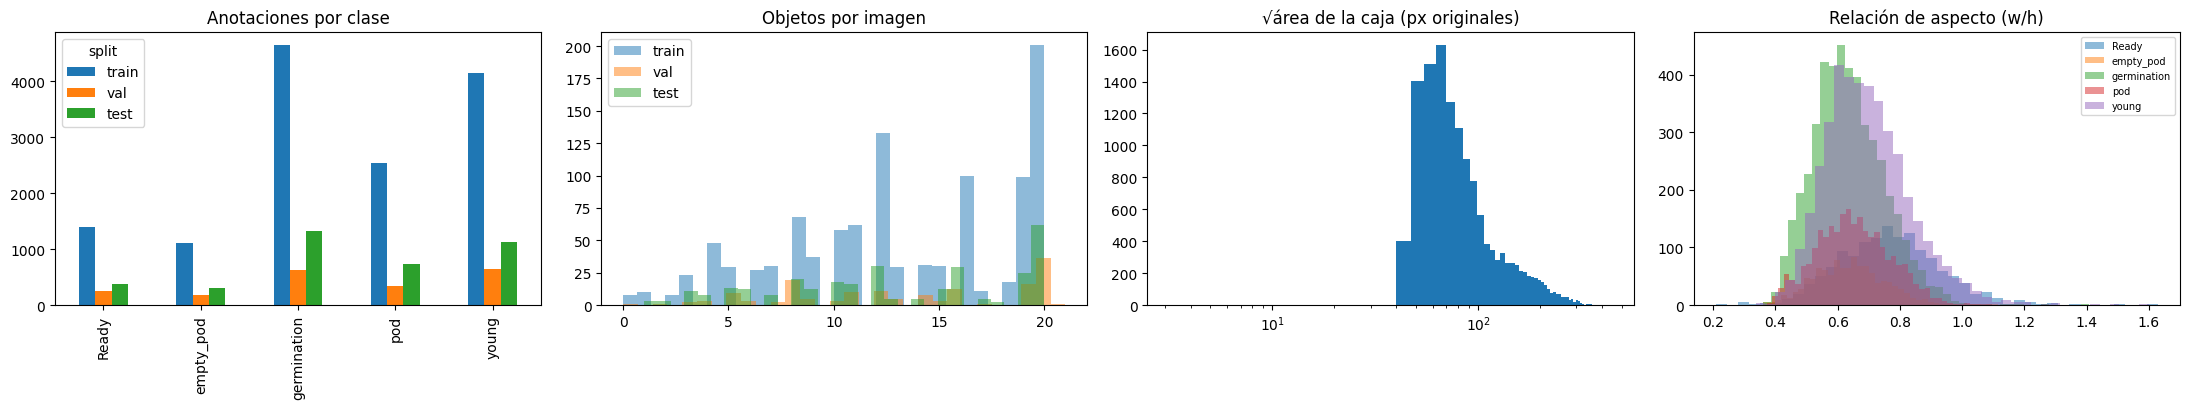

sqrt_area              px_ssd300             
               median   min    max    median   min    max
cls                                                      
Ready           187.2  58.0  444.5      87.8  27.2  208.4
empty_pod        74.2  42.5  135.9      34.8  19.9   63.7
germination      67.7  40.2  157.5      31.7  18.8   73.8
pod              64.1  38.9  242.0      30.0  18.3  113.4
young           123.4   3.2  355.3      57.8   1.5  166.6

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(22, 4.2))

# Mostramos un gráfico de barras con el número de anotaciones por clase para cada split
class_counts[list(SPLITS)].plot.bar(ax=axs[0]); axs[0].set_title("Anotaciones por clase"); axs[0].set_xlabel("")

# Mostramos un histograma con el número de objetos por imagen para cada split
for s in SPLITS:
    cnt = Counter(a["image_id"] for a in COCO_GT[s].anns.values())
    axs[1].hist([cnt.get(i, 0) for i in COCO_GT[s].imgs], bins=30, alpha=.5, label=s)
axs[1].set_title("Objetos por imagen")
axs[1].legend()

# Mostramos un histograma que refleje la distribución del tamaño de los objetos
axs[2].hist(tr["sqrt_area"], bins=60)
axs[2].set_xscale("log")
axs[2].set_title("√área de la caja (px originales)")

# Mostramos un histograma con la relación de aspecto (ancho/alto) de los objetos por clase
for cls in CLASS_NAMES:
    axs[3].hist(tr[tr.cls == cls]["aspect"].clip(0, 4), bins=40, alpha=.5, label=cls)
axs[3].set_title("Relación de aspecto (w/h)")
axs[3].legend(fontsize=7)

plt.tight_layout()
plt.savefig(WORK_DIR / "figs" / "eda_overview.png", dpi=130)
plt.show()

# Mostramos el tamaño medio por clase para ver si hay clases sistemáticamente más pequeñas
# Esto puede ser relevante para la detección, ya que las clases más pequeñas pueden ser más difíciles de detectar para el modelo
display(tr.groupby("cls")[["sqrt_area", "px_ssd300"]].agg(["median", "min", "max"]).round(1).reindex(CLASS_NAMES))

Lo siguiente que haremos será visualizar algunas de las imágenes de entrenamiento con sus respectivos tamaños y anotaciones para echarles un vistazo.

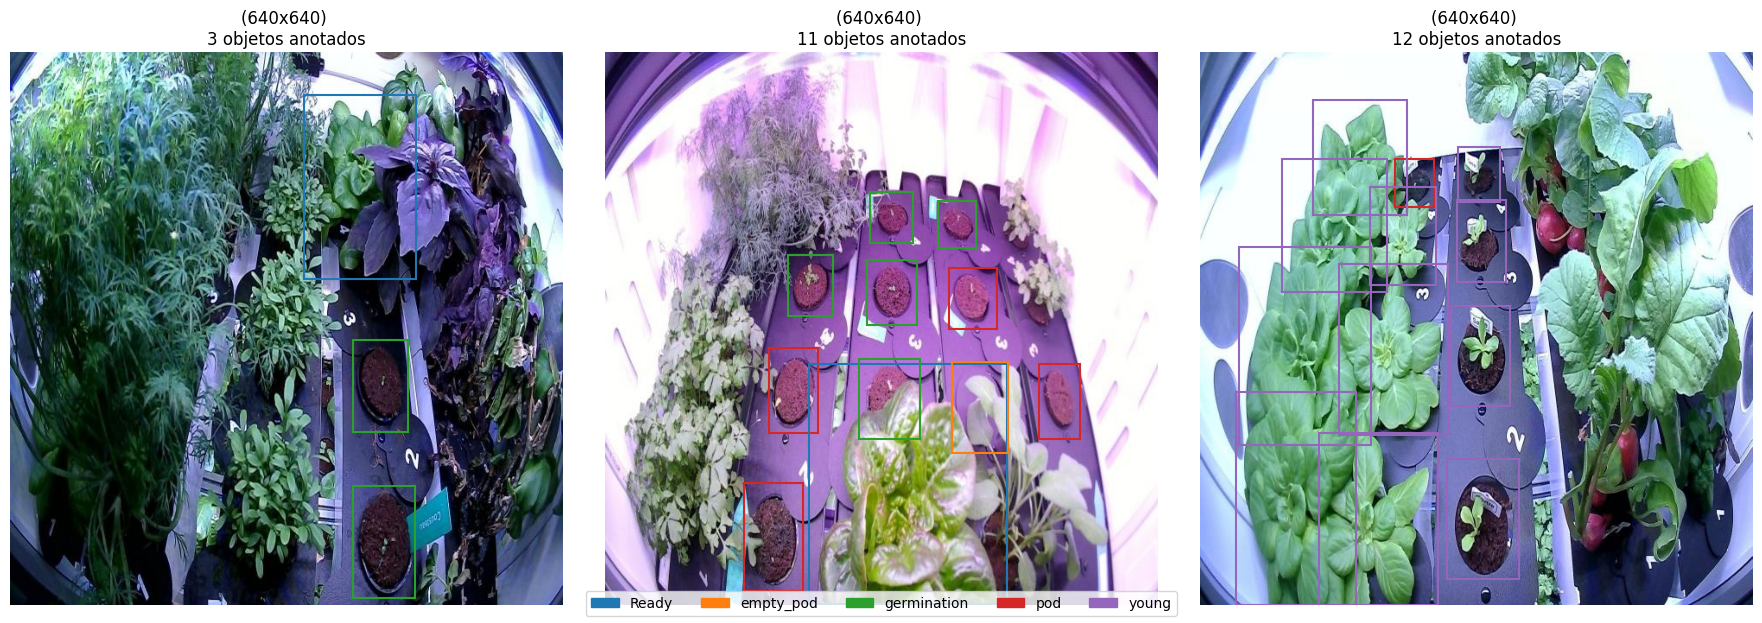

In [ ]:
# Creamos un array de colores para cada clase utilizando el colormap 'tab10' de Matplotlib
CLASS_COLORS = plt.cm.tab10(np.arange(K))

# Dibujamos algunas imágenes de ejemplo con sus anotaciones de bounding boxes para visualizar cómo se ven los objetos anotados en el dataset
def draw_gt(coco, image_dir, image_ids, ncols=3):
    nrows = math.ceil(len(image_ids) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows)); axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis("off")
    for ax, iid in zip(axs, image_ids):
        info = coco.imgs[iid]
        ax.imshow(Image.open(Path(image_dir) / info["file_name"]).convert("RGB"))
        n_obj = 0
        for a in coco.loadAnns(coco.getAnnIds(imgIds=iid)):
            x, y, w, h = a["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=1.5, ec=CLASS_COLORS[CID2IDX[a["category_id"]]]))
            n_obj += 1
        ax.set_title(f"({info['width']}x{info['height']}) \n{n_obj} objetos anotados")
    handles = [patches.Patch(color=CLASS_COLORS[i], label=n) for i, n in enumerate(CLASS_NAMES)]
    fig.legend(handles=handles, loc="lower center", ncol=K)
    plt.tight_layout()
    plt.show()

rng = random.Random(SEED)
draw_gt(COCO_GT["train"], CLEAN["train"]["images"], rng.sample(sorted(COCO_GT["train"].imgs), 3))

Observamos que el conjunto de entrenamiento tiene 1060 imágenes de 640×640 y 13812 anotaciones repartidas en cinco clases. La más frecuente es `germination` (33,7 % de las anotaciones de *train*), seguida de `young` (30,0 %), mientras que `empty_pod` (8,0 %) y `Ready` (10,0 %) son las minoritarias. La diferencia entre la clase más y menos frecuente es de algo más de 4 a 1, lo que supone un desbalance moderado, no extremo.

Según el criterio de tamaño de COCO, el 63,2 % de los objetos son medianos y el 36,8 % grandes, sin prácticamente objetos pequeños. Tras reescalar a 300×300, menos del 0,05 % de los objetos queda por debajo de 16 px, por lo que SSD300 no debería verse perjudicado de forma generalizada por el tamaño. Las excepciones son unas pocas cajas diminutas de la clase `young` (la menor mide apenas 3 px de lado) que posiblemente sean errores de anotación. Serían estas las que harían que el mAP en objetos pequeños no fuese informativo, aunque en este caso no hay problema.

En cuanto a las detecciones, vemos que hay una media de 13 objetos por imagen y un máximo de 20 en *train* y *test* (21 en *val*), con muchas imágenes que llegan justo a 20. El límite de 25 detecciones por imagen (`MAX_DETS`) es, por tanto, lo suficientemente holgado.

Por su parte, en las imágenes que hemos revisado, el reto visual principal no es el tamaño sino el contexto. Las fotos están tomadas con un gran angular con distorsión de ojo de pez en un cultivo con iluminación artificial cuyo tono varía bastante de una imagen a otra. Alrededor de las bandejas hay vegetación de otras plantas que actúa como distractor y las cajas de la clase `young` se solapan con frecuencia entre sí. Además, la vista no es estrictamente cenital. Se aprecia una orientación y una perspectiva claras, de modo que un volteo vertical o un giro de 90° generaría escenas poco realistas. El volteo horizontal sí parece seguro, y el resto de transformaciones geométricas habría que validarlas con los experimentos en lugar de darlas por buenas de cara a las mejoras en los modelos.

## 4. Infraestructura común: dataset, evaluación, tiempos y resultados

Partimos de los JSON limpios (5 clases, ids 1…5, cajas recortadas). Como los `category_id` son contiguos desde 1, la etiqueta que usa torchvision (0 = fondo) coincide con el `category_id` y no hace falta ninguna conversión. Mientras que Detectron2 leerá los mismos JSON directamente, necesitaremos crear el Dataset COCO para torchvision (SSD) y los DataLoaders.

In [ ]:
# Comprobamos que los IDs de las clases sean consecutivos y comiencen en 1
assert CLASS_IDS == list(range(1, K + 1)), "Los ids deben ser 1..K para que label == category_id"

class CocoDetection(Dataset):
    """Dataset COCO para torchvision. Devuelve (imagen [0,1] CxHxW, target con cajas xyxy y etiquetas 1..K)."""
    def __init__(self, coco, image_dir, train=False):
        self.coco = coco
        self.image_dir = Path(image_dir)
        self.ids = sorted(coco.getImgIds())
        self.train = train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        img_id = self.ids[index]
        info = self.coco.imgs[img_id]
        image = Image.open(self.image_dir / info["file_name"]).convert("RGB")
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))

        boxes  = [[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in anns]
        labels = [a["category_id"] for a in anns]

        image = TF.to_tensor(image)
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),  # reshape: imágenes sin objetos
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([img_id]),
        }

        if self.train:
            pass # aquí se aplicaría el aumento de datos, pero nuestro baseline no lo usa

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Un Dataset por split, reutilizando los objetos COCO de ground truth ya cargados
DS = {s: CocoDetection(COCO_GT[s], CLEAN[s]["images"], train=(s == "train")) for s in SPLITS}

BATCH_SSD = 4
NUM_WORKERS = 2
train_loader = DataLoader(DS["train"], batch_size=BATCH_SSD, shuffle=True, collate_fn=collate_fn,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=make_generator())
val_loader = DataLoader(DS["val"], batch_size=BATCH_SSD, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)
print({s: len(DS[s]) for s in SPLITS})

{'train': 1060, 'val': 151, 'test': 299}


Seguidamente, definimos la evaluación común a ambos detectores. Recibe las predicciones en formato COCO y calcula el mAP@[.5:.95], el mAP@.5, el mAP@.75, el mAP por tamaño de objeto y el AP por clase con `COCOeval`, usando `maxDets = [1, 10, MAX_DETS]`. Las métricas se obtienen directamente del tensor de precisión que devuelve `COCOeval` y no de `ev.stats`, ya que con un `maxDets` distinto del habitual (100), `summarize()` nos devolvía -1 para el mAP@[.5:.95].

Junto a la evaluación, definimos tres utilidades para que los dos detectores se traten exactamente igual:
- `print_metrics` imprime el informe de cada experimento siempre con el mismo formato.
- `evaluate_and_report` guarda las predicciones, evalúa, registra el resultado en `results.csv` y lanza ese informe.
- `time_inference` mide el tiempo de inferencia con un único protocolo: lote de una imagen, imágenes ya cargadas en memoria, calentamiento previo y sincronización de la GPU. Los tiempos se miden así, y no dentro del bucle de evaluación, para que ni la lectura de disco ni el tamaño del lote influyan en la comparación de velocidad entre arquitecturas.

In [ ]:
METRIC_NAMES = ["mAP", "mAP50", "mAP75", "mAP_small", "mAP_medium", "mAP_large"]

def run_cocoeval(coco_gt, predictions, max_dets=MAX_DETS):
    """Ejecuta COCOeval (bbox) sin imprimir nada y devuelve el objeto con los tensores de precisión y recall."""
    with contextlib.redirect_stdout(io.StringIO()):
        coco_dt = coco_gt.loadRes(predictions)
        ev = COCOeval(coco_gt, coco_dt, "bbox")
        ev.params.maxDets = [1, 10, max_dets]
        ev.evaluate(); ev.accumulate()
    return ev

def _mean_valid(x):
    """Media de los valores válidos (COCOeval marca con -1 lo que no se puede calcular)."""
    x = np.asarray(x); x = x[x > -1]
    return float(x.mean()) if x.size else float("nan")

def evaluate_coco(coco_gt, predictions, max_dets=MAX_DETS):
    """Evaluación COCO (bbox) idéntica para SSD y Cascade R-CNN.
    Las métricas se calculan directamente sobre el tensor de precisión [T, R, K, A, M].
    No usamos ev.stats[0] porque COCOeval.summarize() fija maxDets=100 para el mAP@[.5:.95] y,
    al haber definido maxDets=[1, 10, 25], ese valor saldría como -1."""
    # Si no hay predicciones, devolvemos 0.0 para todas las métricas
    if not predictions:
        return {**{n: 0.0 for n in METRIC_NAMES}, **{f"AP_{c}": 0.0 for c in CLASS_NAMES}}
    
    # Ejecutamos COCOeval y obtenemos el tensor de precisión
    ev = run_cocoeval(coco_gt, predictions, max_dets)
    prec = ev.eval["precision"][..., 2] # [T, R, K, A] -> [Umbral de confianza de IoU, Umbral de recall, Clase, Área (Small, Medium, Large)]
                                        # M=2 -> max_dets
    
    # Calculamos los índices de IoU para 0.50 y 0.75
    iou = ev.params.iouThrs
    t50, t75 = int(np.argmin(np.abs(iou - 0.50))), int(np.argmin(np.abs(iou - 0.75)))
    
    # Calculamos las métricas de mAP y AP por clase utilizando la función _mean_valid para ignorar los valores no válidos (-1)
    m = {"mAP":        _mean_valid(prec[:, :, :, 0]), # A=0: todas las áreas
         "mAP50":      _mean_valid(prec[t50, :, :, 0]),
         "mAP75":      _mean_valid(prec[t75, :, :, 0]),
         "mAP_small":  _mean_valid(prec[:, :, :, 1]),
         "mAP_medium": _mean_valid(prec[:, :, :, 2]),
         "mAP_large":  _mean_valid(prec[:, :, :, 3])}
    for k, cname in enumerate(CLASS_NAMES): # los catIds de COCOeval van ordenados = CLASS_IDS
        m[f"AP_{cname}"] = _mean_valid(prec[:, :, k, 0])
    return m

RESULTS_CSV = WORK_DIR / "results.csv" # archivo CSV donde se guardan los resultados de los experimentos

# Función para registrar los resultados de un experimento en un archivo CSV
def log_result(exp, detector, split, metrics, train_time_s=float("nan"), infer_ms_img=float("nan"), params_m=float("nan")):
    """Añade (o sustituye) una fila en results.csv y devuelve la tabla completa."""
    row = {"exp": exp, "detector": detector, "split": split, **metrics,
           "train_min": round(train_time_s / 60, 1), "infer_ms_img": round(infer_ms_img, 1),
           "params_M": round(params_m, 1)}
    df = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()
    if len(df):
        df = df[~((df["exp"] == exp) & (df["split"] == split))]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        df = pd.DataFrame([row])
    df.to_csv(RESULTS_CSV, index=False)
    return df

# Sincronizamos la GPU para medir correctamente el tiempo de inferencia
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

def count_params(model):
    """Número de parámetros (en millones)."""
    return sum(p.numel() for p in model.parameters()) / 1e6

@torch.no_grad()
def time_inference(infer_fn, coco_gt, image_dir, n=100, warmup=10):
    """Tiempo medio de inferencia (ms/imagen) con el MISMO protocolo para cualquier detector:
    batch de 1 imagen, imágenes ya cargadas en memoria (no se mide la lectura de disco), calentamiento previo
    y sincronización de la GPU. Incluye el preprocesado, la red y el post-procesado (NMS) propios de cada detector.
    infer_fn recibe una imagen RGB uint8 (H, W, 3) como array de NumPy."""
    ids = sorted(coco_gt.imgs)[: n + warmup]
    imgs = [np.array(Image.open(Path(image_dir) / coco_gt.imgs[i]["file_name"]).convert("RGB")) for i in ids]
    for im in imgs[:warmup]:
        infer_fn(im)
    sync(); t0 = time.perf_counter()
    for im in imgs[warmup:]:
        infer_fn(im)
    sync()
    return 1000 * (time.perf_counter() - t0) / len(imgs[warmup:])

def print_metrics(exp, split, m, infer_ms=float("nan"), train_s=float("nan"), params_m=float("nan"), coco_gt=None):
    """Informe con el mismo formato para todos los detectores y experimentos."""
    line = "═" * 86
    n_small = sum(a["area"] < 32 ** 2 for a in coco_gt.anns.values()) if coco_gt is not None else None
    print(line); print(f" {exp}   |   split: {split}"); print(line)
    print(f" mAP@[.5:.95] = {m['mAP']:.3f}    mAP@.50 = {m['mAP50']:.3f}    mAP@.75 = {m['mAP75']:.3f}")
    nota = f"   (solo {n_small} objetos small en el GT: poco fiable)" if n_small is not None and n_small < 30 else ""
    print(f" Por tamaño:   small = {m['mAP_small']:.3f}    medium = {m['mAP_medium']:.3f}    large = {m['mAP_large']:.3f}{nota}")
    print(" AP por clase: " + "    ".join(f"{c} = {m[f'AP_{c}']:.3f}" for c in CLASS_NAMES))
    print(f" Coste:        {infer_ms:.1f} ms/img ({1000 / infer_ms:.1f} FPS)    entrenamiento = {train_s / 60:.1f} min    "
          f"{params_m:.1f} M parámetros\n")

def evaluate_and_report(tag, exp, detector, split, preds, infer_ms, train_s, params_m):
    """Guardamos las predicciones, evaluamos, registramos en results.csv e imprimimos el informe común."""
    (WORK_DIR / "preds" / f"{tag}_{split}.json").write_text(json.dumps(preds))
    m = evaluate_coco(COCO_GT[split], preds)
    log_result(exp, detector, split, m, train_s, infer_ms, params_m)
    print_metrics(exp, split, m, infer_ms, train_s, params_m, COCO_GT[split])
    return m

## 5. Baseline SSD300 (torchvision)

Construimos el detector SSD300 con VGG16 como backbone, con pesos preentrenados en COCO, y sustituimos la cabeza de clasificación por una nueva para nuestras `K` clases (+1 de fondo).
Los umbrales de inferencia (`score_thresh`, `nms_thresh`, `detections_per_img`) son los comunes definidos en la configuración.

In [18]:
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd(pretrained=True):
    weights = SSD300_VGG16_Weights.COCO_V1 if pretrained else None
    model = ssd300_vgg16(weights=weights, score_thresh=SCORE_THRESH_EVAL,
                         nms_thresh=NMS_IOU, detections_per_img=MAX_DETS)

    # Canales de entrada de cada nivel de características y nº de anchors por posición
    in_channels = [layer.in_channels for layer in model.head.classification_head.module_list]
    num_anchors = model.anchor_generator.num_anchors_per_location()

    # Sustituimos la cabeza de clasificación para nuestras clases (+1 para fondo)
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels, num_anchors=num_anchors, num_classes=K + 1)
    return model

seed_everything()
ssd = build_ssd(PRETRAINED).to(DEVICE)
print("SSD300 preparado correctamente.")

SSD300 preparado correctamente.


Entrenamos el baseline con SGD (*momentum = 0,9* y *weight decay = 5e-4*) y una *tasa de aprendizaje inicial de 0,002* que se divide entre 10 cada 5 épocas (`StepLR`), durante *15 épocas* y *sin aumento* de datos. Esta es la configuración clásica para SSD y la mantenemos sin tocar para que el baseline sea un punto de partida limpio frente al que medir cada mejora. Añadimos un *recorte de gradiente* (norma máxima 10) para evitar divergencias en las primeras épocas, cuando la cabeza de clasificación nueva todavía está inicializada al azar.

SSD epoch 1/15: train=3.8287 val=2.6130
SSD epoch 2/15: train=2.3274 val=2.2868
SSD epoch 3/15: train=1.9373 val=2.0726
SSD epoch 4/15: train=1.6602 val=1.9341
SSD epoch 5/15: train=1.4706 val=1.8812
SSD epoch 6/15: train=1.1368 val=1.7149
SSD epoch 7/15: train=1.0597 val=1.7008
SSD epoch 8/15: train=1.0240 val=1.6973
SSD epoch 9/15: train=0.9891 val=1.7033
SSD epoch 10/15: train=0.9614 val=1.7085
SSD epoch 11/15: train=0.9219 val=1.7143
SSD epoch 12/15: train=0.9180 val=1.7181
SSD epoch 13/15: train=0.9141 val=1.7197
SSD epoch 14/15: train=0.9138 val=1.7202
SSD epoch 15/15: train=0.9098 val=1.7219


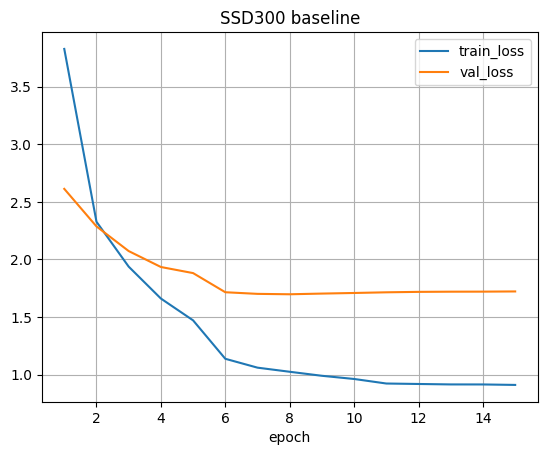

Tiempo de entrenamiento: 20.3 min


In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train(); losses = []
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def mean_detection_loss(model, loader, device):
    # Torchvision solo calcula la loss en modo train
    # No se actualizan gradientes
    model.train(); vals = []
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        vals.append(float(sum(model(images, targets).values()).cpu()))
    model.eval()
    return float(np.mean(vals))

EPOCHS_SSD = 15
LR_SSD = 0.002
SSD_CKPT = WORK_DIR / "ckpt" / "ssd300_baseline.pth"
SSD_HIST = WORK_DIR / "ckpt" / "ssd300_baseline_history.json"

# Entrenamiento de SSD300
if SSD_CKPT.exists() and SSD_HIST.exists():
    info = json.loads(SSD_HIST.read_text())
    history_ssd, ssd_train_time = info["history"], info["train_time_s"]
    ssd.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE))
    print(f"Checkpoint SSD reutilizado ({SSD_CKPT})")
else:
    optimizer = torch.optim.SGD([p for p in ssd.parameters() if p.requires_grad],
                                lr=LR_SSD, momentum=0.9, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
    history_ssd, best_val = [], float("inf")
    sync(); t0 = time.time()
    for epoch in range(EPOCHS_SSD):
        tr = train_one_epoch(ssd, train_loader, optimizer, DEVICE)
        vl = mean_detection_loss(ssd, val_loader, DEVICE)
        scheduler.step()
        history_ssd.append({"epoch": epoch + 1, "train_loss": tr, "val_loss": vl})
        print(f"SSD epoch {epoch+1}/{EPOCHS_SSD}: train={tr:.4f} val={vl:.4f}")
        if vl < best_val:
            best_val = vl
            torch.save(ssd.state_dict(), SSD_CKPT)
    sync(); ssd_train_time = time.time() - t0
    SSD_HIST.write_text(json.dumps({"history": history_ssd, "train_time_s": ssd_train_time}))
    ssd.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE)) # nos quedamos con el mejor en val

ssd.eval()
pd.DataFrame(history_ssd).plot(x="epoch", y=["train_loss", "val_loss"], grid=True, title="SSD300 baseline")
plt.savefig(WORK_DIR / "figs" / "ssd_baseline_loss.png", dpi=130)
plt.show()
print(f"Tiempo de entrenamiento: {ssd_train_time/60:.1f} min")

Como torchvision solo calcula la pérdida en modo entrenamiento, la pérdida de validación se obtiene pasando el modelo a `train()` sin actualizar los pesos. Nos quedamos con el checkpoint de menor pérdida de validación, y vemos que la decisión tiene efecto real. Como se aprecia en la curva, a partir de la época 8 la pérdida de validación deja de bajar y sube ligeramente, mientras la de entrenamiento sigue descendiendo, un indicio de sobreajuste. Si ya existe un checkpoint en `work/ckpt`, se reutiliza en lugar de volver a entrenar.

Evaluamos ahora SSD300 en *val* y *test* con la evaluación común. Las predicciones se calculan por lotes de 4 imágenes, algo que no afecta al resultado porque SSD reescala cada imagen a 300×300, y el tiempo de inferencia se mide aparte con `time_inference` para que sea comparable con el de Cascade R-CNN.

In [ ]:
@torch.no_grad()
def predict_ssd(model, dataset, batch_size=4):
    """Predicciones en formato COCO. El tiempo no se mide aquí sino con time_inference."""
    model.eval(); preds = []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_fn)
    for images, targets in loader:
        outputs = model([im.to(DEVICE) for im in images])
        for target, out in zip(targets, outputs):
            image_id = int(target["image_id"].item())
            for (x1, y1, x2, y2), score, label in zip(out["boxes"].cpu().tolist(),
                                                      out["scores"].cpu().tolist(),
                                                      out["labels"].cpu().tolist()):
                preds.append({"image_id": image_id, "category_id": CLASS_IDS[int(label) - 1], # label 1..K
                              "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(score)})
    return preds

ssd.eval()
ssd_ms = time_inference(lambda im: ssd([TF.to_tensor(im).to(DEVICE)]), COCO_GT["test"], CLEAN["test"]["images"])
ssd_params = count_params(ssd)

for split in ("val", "test"):
    preds = predict_ssd(ssd, DS[split])
    evaluate_and_report("ssd300_baseline", "SSD300 baseline", "SSD300", split, preds, ssd_ms, ssd_train_time, ssd_params)

# Liberamos la GPU antes de entrenar Cascade R-CNN
del ssd; gc.collect()
torch.cuda.empty_cache()

══════════════════════════════════════════════════════════════════════════════════════
 SSD300 baseline   |   split: val
══════════════════════════════════════════════════════════════════════════════════════
 mAP@[.5:.95] = 0.660    mAP@.50 = 0.946    mAP@.75 = 0.801
 Por tamaño:   small = 0.000    medium = 0.687    large = 0.701   (solo 1 objetos small en el GT: poco fiable)
 AP por clase: Ready = 0.494    empty_pod = 0.732    germination = 0.717    pod = 0.726    young = 0.630
 Coste:        36.4 ms/img (27.5 FPS)    entrenamiento = 20.3 min    24.3 M parámetros

══════════════════════════════════════════════════════════════════════════════════════
 SSD300 baseline   |   split: test
══════════════════════════════════════════════════════════════════════════════════════
 mAP@[.5:.95] = 0.654    mAP@.50 = 0.940    mAP@.75 = 0.795
 Por tamaño:   small = 0.000    medium = 0.615    large = 0.661   (solo 2 objetos small en el GT: poco fiable)
 AP por clase: Ready = 0.512    empty_pod = 0.67

## 6. Baseline Cascade R-CNN (Detectron2)

Lo siguiente que haremos será registrar los JSON limpios en Detectron2 y configurar Cascade R-CNN (R-50-FPN, 3x) con los pesos de COCO, sin la cabeza de máscaras (`MASK_ON = False`), con *5 clases* y con los mismos umbrales de inferencia que SSD (*puntuación mínima = 0,001*, *NMS a 0,5* y *300 detecciones por imagen*), para que la comparación sea justa.

Los hiperparámetros del baseline son los habituales del *fine-tuning* en Detectron2 con poca memoria de GPU: *lotes de 2 imágenes* (`IMS_PER_BATCH = 2`) y `BASE_LR = 0,00025`, un valor conservador que evita desestabilizar los pesos preentrenados. El número de iteraciones se fija en `MAX_ITER = max(500, N_train/2 · 10)`, es decir, unas 10 épocas (5300 iteraciones), y la tasa de aprendizaje se divide entre 10 al 70 % y al 90 % del entrenamiento. Detectron2 aplica además un calentamiento lineal durante las primeras 1000 iteraciones.

Debemos matizar que Detectron2 aplica por defecto un volteo horizontal aleatorio durante el entrenamiento, por lo que este baseline no es estrictamente "sin aumento de datos" como el de SSD. La última línea de la celda siguiente imprime la configuración de `INPUT` para dejarlo documentado, y lo tendremos en cuenta al interpretar las diferencias entre detectores.

Usamos un `Trainer` propio con `build_evaluator`, necesario para que la evaluación periódica en *val* (`TEST.EVAL_PERIOD`) funcione con `DefaultTrainer`.

In [ ]:
# Registro de los splits limpios en Detectron2
for split in SPLITS:
    name = f"lettuce_{split}"
    if name in DatasetCatalog.list(): DatasetCatalog.remove(name)
    register_coco_instances(name, {}, str(CLEAN[split]["json"]), str(CLEAN[split]["images"]))
    MetadataCatalog.get(name).set(thing_classes=CLASS_NAMES)

# Configuración de Cascade R-CNN
CASCADE_CONFIG = "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml"
CASCADE_DIR = WORK_DIR / "d2" / "cascade_baseline"
CASCADE_DIR.mkdir(parents=True, exist_ok=True)

# Configuración de Cascade R-CNN para nuestro dataset
def make_cascade_cfg(output_dir):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(CASCADE_CONFIG))
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CASCADE_CONFIG) if PRETRAINED else ""
    cfg.MODEL.MASK_ON = False
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = K
    cfg.DATASETS.TRAIN = ("lettuce_train",)
    cfg.DATASETS.TEST = ("lettuce_val",)
    cfg.DATALOADER.NUM_WORKERS = NUM_WORKERS
    cfg.SEED = SEED
    cfg.SOLVER.IMS_PER_BATCH = 2
    cfg.SOLVER.BASE_LR = 0.00025
    cfg.SOLVER.MAX_ITER = max(500, len(DS["train"]) // 2 * 10)
    cfg.SOLVER.STEPS = (int(cfg.SOLVER.MAX_ITER * 0.7), int(cfg.SOLVER.MAX_ITER * 0.9))
    cfg.SOLVER.CHECKPOINT_PERIOD = max(100, cfg.SOLVER.MAX_ITER // 3)
    cfg.TEST.EVAL_PERIOD = max(100, cfg.SOLVER.MAX_ITER // 5)
    # Umbrales de inferencia comunes con SSD
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESH_EVAL
    cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = NMS_IOU
    cfg.TEST.DETECTIONS_PER_IMAGE = MAX_DETS
    cfg.OUTPUT_DIR = str(output_dir)
    return cfg

# Creamos una clase de entrenador personalizada para Cascade R-CNN que utiliza COCOEvaluator
class CascadeTrainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name):
        return COCOEvaluator(dataset_name, distributed=False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval"))

# Creamos la configuración de Cascade R-CNN y mostramos algunos parámetros importantes
cfg = make_cascade_cfg(CASCADE_DIR)
CASCADE_FINAL = CASCADE_DIR / "model_final.pth"
CASCADE_TIME = CASCADE_DIR / "train_time.json"
print(f"MAX_ITER={cfg.SOLVER.MAX_ITER} | STEPS={cfg.SOLVER.STEPS} | EVAL_PERIOD={cfg.TEST.EVAL_PERIOD}")

# Transformaciones que Detectron2 aplica por su cuenta
print(f"INPUT -> RANDOM_FLIP={cfg.INPUT.RANDOM_FLIP} | MIN_SIZE_TRAIN={cfg.INPUT.MIN_SIZE_TRAIN} | MIN_SIZE_TEST={cfg.INPUT.MIN_SIZE_TEST}")

MAX_ITER=5300 | STEPS=(3709, 4770) | EVAL_PERIOD=1060
INPUT -> RANDOM_FLIP=horizontal | MIN_SIZE_TRAIN=(640, 672, 704, 736, 768, 800) | MIN_SIZE_TEST=800


In [ ]:
# Realizamos el entrenamiento de Cascade R-CNN, reutilizando el checkpoint si ya existe
# Si el checkpoint final y el tiempo de entrenamiento ya existen, se reutilizan para evitar volver a entrenar desde cero
if CASCADE_FINAL.exists() and CASCADE_TIME.exists():
    cascade_train_time = json.loads(CASCADE_TIME.read_text())["train_time_s"]
    print(f"Checkpoint Cascade reutilizado ({CASCADE_FINAL})")
else:
    seed_everything()
    trainer = CascadeTrainer(cfg)
    trainer.resume_or_load(resume=True) # reanuda desde el último checkpoint si la sesión se interrumpió
    sync()
    t0 = time.time()
    trainer.train()
    sync()
    cascade_train_time = time.time() - t0 # si se reanudó, solo cuenta el tiempo de esta sesión
    CASCADE_TIME.write_text(json.dumps({"train_time_s": cascade_train_time}))
    del trainer; gc.collect()
    torch.cuda.empty_cache()
print(f"Tiempo de entrenamiento: {cascade_train_time/60:.1f} min")

[11/25 11:26:41 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

model_final_480dd8.pkl: 288MB [00:01, 225MB/s]                            
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.2.cls_score.weight' to the mo

[11/25 11:26:43 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1125 11:26:45.030000 610 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[11/25 11:26:58 d2.utils.events]:  eta: 1:02:33  iter: 19  total_loss: 7.469  loss_cls_stage0: 1.748  loss_box_reg_stage0: 0.6343  loss_cls_stage1: 1.722  loss_box_reg_stage1: 0.7224  loss_cls_stage2: 1.664  loss_box_reg_stage2: 0.331  loss_rpn_cls: 0.3186  loss_rpn_loc: 0.105    time: 0.7004  last_time: 0.5997  data_time: 0.0132  last_data_time: 0.0051   lr: 4.9953e-06  max_mem: 2352M


I0000 00:00:1795606035.291777     610 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


[11/25 11:27:33 d2.utils.events]:  eta: 1:02:21  iter: 39  total_loss: 7.309  loss_cls_stage0: 1.688  loss_box_reg_stage0: 0.6715  loss_cls_stage1: 1.662  loss_box_reg_stage1: 0.8234  loss_cls_stage2: 1.602  loss_box_reg_stage2: 0.3867  loss_rpn_cls: 0.3429  loss_rpn_loc: 0.1007    time: 0.7077  last_time: 0.7969  data_time: 0.0059  last_data_time: 0.0062   lr: 9.9902e-06  max_mem: 2353M
[11/25 11:27:48 d2.utils.events]:  eta: 1:04:00  iter: 59  total_loss: 6.752  loss_cls_stage0: 1.557  loss_box_reg_stage0: 0.6499  loss_cls_stage1: 1.54  loss_box_reg_stage1: 0.7962  loss_cls_stage2: 1.444  loss_box_reg_stage2: 0.425  loss_rpn_cls: 0.2197  loss_rpn_loc: 0.0948    time: 0.7247  last_time: 0.7682  data_time: 0.0062  last_data_time: 0.0063   lr: 1.4985e-05  max_mem: 2353M
[11/25 11:28:01 d2.utils.events]:  eta: 1:01:52  iter: 79  total_loss: 6.408  loss_cls_stage0: 1.388  loss_box_reg_stage0: 0.6178  loss_cls_stage1: 1.377  loss_box_reg_stage1: 0.8484  loss_cls_stage2: 1.273  loss_box_reg

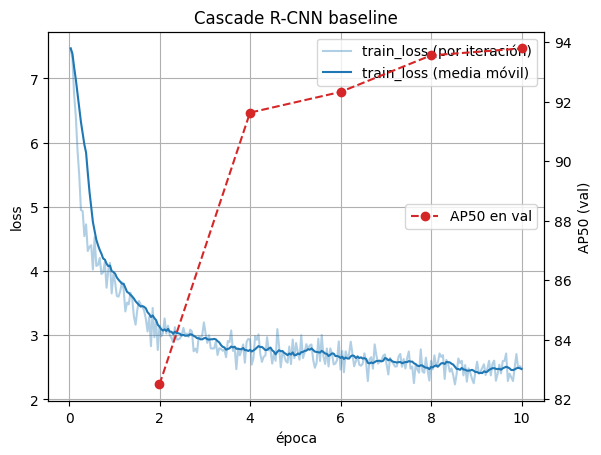

In [ ]:
# Detectron2 escribe un metrics.json con la pérdida de entrenamiento y el AP50 en val cada EVAL_PERIOD iteraciones, con el eje en épocas como en SSD
mj = CASCADE_DIR / "metrics.json"
if mj.exists():
    rows = [json.loads(l) for l in mj.read_text().splitlines() if l.strip()]
    iters_per_epoch = len(DS["train"]) / cfg.SOLVER.IMS_PER_BATCH
    tr = pd.DataFrame([{"epoch": r["iteration"] / iters_per_epoch, "train_loss": r["total_loss"]} for r in rows if "total_loss" in r])
    fig, ax = plt.subplots()
    ax.plot(tr.epoch, tr.train_loss, alpha=0.35, label="train_loss (por iteración)")
    ax.plot(tr.epoch, tr.train_loss.rolling(10, min_periods=1).mean(), color="C0", label="train_loss (media móvil)")
    
    # Detectron2 no calcula la pérdida de validación, en su lugar evalúa el AP50 en val cada EVAL_PERIOD iteraciones
    val = [(r["iteration"] / iters_per_epoch, r["bbox/AP50"]) for r in rows if "bbox/AP50" in r]
    if val:
        ax2 = ax.twinx(); ax2.plot(*zip(*val), "o--", color="C3", label="AP50 en val"); ax2.set_ylabel("AP50 (val)")
        ax2.legend(loc="center right")
    ax.set_xlabel("época"); ax.set_ylabel("loss"); ax.grid(True); ax.legend(loc="upper right")
    ax.set_title("Cascade R-CNN baseline")
    plt.savefig(WORK_DIR / "figs" / "cascade_baseline_loss.png", dpi=130); plt.show()

Vemos que el entrenamiento de Cascade R-CNN ha finalizado y se han registrado las métricas de pérdida y AP50 en *validación*. La sencillez de la configuración se refleja en la curva de pérdida, que muestra que, mientras el AP50 continúa ascendiendo, la pérdida sigue bajando lentamente al final, de modo que la tasa de aprendizaje y la duración del entrenamiento son candidatos en la fase de mejoras.

Los resultados de AP50 en el gráfico muestran un aumento constante de esta métrica, lo que indica una mejora en la capacidad del modelo para detectar y localizar objetos en imágenes que no ha visto en el entrenamiento. Estes resultados son los mismos que los que se obtienen al evaluar las predicciones finales del modelo entrenado, mas no incluyen el AP@[.5:.95] ni el AP por clase. Por eso, a continuación, evaluamos el modelo final de Cascade R-CNN en los splits de *validación* y *test*, y registramos los resultados en `results.csv`.

Evaluamos Cascade R-CNN con el mismo `evaluate_coco` que SSD y el mismo informe. Las predicciones se generan con `DefaultPredictor`, que espera imágenes en BGR y por eso las leemos con OpenCV, y el tiempo se mide con `time_inference`, convirtiendo cada imagen a BGR dentro de la función de inferencia. Hay que tener en cuenta que Detectron2 reescala las imágenes de test a 800 px por el lado corto, frente a los 300×300 de SSD, y que eso influye tanto en la precisión como en el tiempo de inferencia.

In [ ]:
def predict_d2(predictor, coco_gt, image_dir):
    """Predicciones en formato COCO. El tiempo no se mide aquí sino con time_inference."""
    preds = []
    for iid in sorted(coco_gt.imgs):
        img = cv2.imread(str(Path(image_dir) / coco_gt.imgs[iid]["file_name"])) # BGR
        inst = predictor(img)["instances"].to("cpu")
        boxes = inst.pred_boxes.tensor.numpy(); scores = inst.scores.numpy(); classes = inst.pred_classes.numpy()
        for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
            preds.append({"image_id": int(iid), "category_id": CLASS_IDS[int(c)],
                          "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)})
    return preds

cfg.MODEL.WEIGHTS = str(CASCADE_FINAL)
predictor = DefaultPredictor(cfg)

# time_inference entrega imágenes RGB
# DefaultPredictor espera BGR
cascade_ms = time_inference(lambda im: predictor(np.ascontiguousarray(im[:, :, ::-1])), COCO_GT["test"], CLEAN["test"]["images"])
cascade_params = count_params(predictor.model)

for split in ("val", "test"):
    preds = predict_d2(predictor, COCO_GT[split], CLEAN[split]["images"])
    evaluate_and_report("cascade_baseline", "Cascade R-CNN baseline", "Cascade R-CNN", split, preds, cascade_ms, cascade_train_time, cascade_params)

[11/25 12:29:34 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /kaggle/working/work/d2/cascade_baseline/model_final.pth ...
══════════════════════════════════════════════════════════════════════════════════════
 Cascade R-CNN baseline   |   split: val
══════════════════════════════════════════════════════════════════════════════════════
 mAP@[.5:.95] = 0.665    mAP@.50 = 0.938    mAP@.75 = 0.796
 Por tamaño:   small = 0.000    medium = 0.710    large = 0.688   (solo 1 objetos small en el GT: poco fiable)
 AP por clase: Ready = 0.472    empty_pod = 0.711    germination = 0.729    pod = 0.751    young = 0.663
 Coste:        171.3 ms/img (5.8 FPS)    entrenamiento = 62.8 min    69.1 M parámetros

══════════════════════════════════════════════════════════════════════════════════════
 Cascade R-CNN baseline   |   split: test
══════════════════════════════════════════════════════════════════════════════════════
 mAP@[.5:.95] = 0.660    mAP@.50 = 0.926    mAP@.75 = 

## 7. Comparativa de los baselines: SSD300 vs Cascade R-CNN

Reunimos los resultados de ambos detectores en esta sección. Las decisiones se toman con *val* y la cifra que se reporta es la de *test*. Partimos de `results.csv`, que acumula todos los experimentos, y de las predicciones guardadas en `work/preds`.

La tabla resume la precisión y el coste de cada detector en *test* y en *val*, con el mejor valor de cada columna resaltado en rojo. Las columnas ΔmAP y ΔmAP50 miden la diferencia respecto al baseline del mismo detector, así que valen 0 en los baselines y servirán para cuantificar cada mejora que se pruebe. Los tiempos de inferencia se miden con el protocolo común de `time_inference` y son comparables entre detectores, aunque no deben leerse solo como una propiedad de la arquitectura, ya que SSD300 procesa imágenes de 300×300 y Cascade R-CNN de 800 px por el lado corto.

In [ ]:
# Experimentos que se comparan: nombre en results.csv -> prefijo de los ficheros de predicciones en work/preds
EXP_TAGS = {"SSD300 baseline": "ssd300_baseline", "Cascade R-CNN baseline": "cascade_baseline"}
EXP_COLORS = dict(zip(EXP_TAGS, plt.cm.tab10(np.arange(len(EXP_TAGS))))) # colores para cada experimento en los gráficos

res = pd.read_csv(RESULTS_CSV)
res = res[res.exp.isin(EXP_TAGS)].copy()
res["FPS"] = 1000 / res["infer_ms_img"]

# Diferencia de cada experimento respecto al baseline de su mismo detector
base = res[res.exp.str.contains("baseline", case=False)].set_index(["detector", "split"])
for k in ("mAP", "mAP50"):
    res[f"Δ{k}"] = [r[k] - base.loc[(r["detector"], r["split"]), k] for _, r in res.iterrows()]

# Mostramos los resultados de cada experimento en test y val, resaltado de los mejores resultados
QUALITY = ["mAP", "mAP50", "mAP75", "mAP_medium", "mAP_large"]
COST = ["train_min", "infer_ms_img", "FPS", "params_M"]
for split in ("test", "val"):
    t = res[res.split == split].set_index("exp").loc[list(EXP_TAGS), ["detector"] + QUALITY + ["ΔmAP", "ΔmAP50"] + COST]
    print(f"\n{'RESULTADOS EN ' + split.upper()}")
    try:
        display(t.style.format("{:.3f}", subset=QUALITY).format("{:+.3f}", subset=["ΔmAP", "ΔmAP50"])
                 .format("{:.1f}", subset=COST)
                 .highlight_max(subset=QUALITY + ["FPS"], color="red")
                 .highlight_min(subset=["train_min", "infer_ms_img", "params_M"], color="red"))
    except Exception:
        display(t.round(3))


RESULTADOS EN TEST  (cifra a reportar)


,detector,mAP,mAP50,mAP75,mAP_medium,mAP_large,ΔmAP,ΔmAP50,train_min,infer_ms_img,FPS,params_M
exp,,,,,,,,,,,,
SSD300 baseline,SSD300,0.654,0.940,0.795,0.615,0.661,+0.000,+0.000,20.3,36.4,27.5,24.3
Cascade R-CNN baseline,Cascade R-CNN,0.660,0.926,0.804,0.598,0.657,+0.000,+0.000,62.8,171.3,5.8,69.1



RESULTADOS EN VAL  (se usa para decidir)


,detector,mAP,mAP50,mAP75,mAP_medium,mAP_large,ΔmAP,ΔmAP50,train_min,infer_ms_img,FPS,params_M
exp,,,,,,,,,,,,
SSD300 baseline,SSD300,0.660,0.946,0.801,0.687,0.701,+0.000,+0.000,20.3,36.4,27.5,24.3
Cascade R-CNN baseline,Cascade R-CNN,0.665,0.938,0.796,0.710,0.688,+0.000,+0.000,62.8,171.3,5.8,69.1


En términos de precisión global, ambos modelos presentan resultados prácticamente equivalentes. Cascade R-CNN obtiene una ligera ventaja en mAP@[.5:.95] (mAP), tanto en validación como en test, pero las diferencias son inferiores a un punto porcentual. Dado que se ha realizado un único entrenamiento por modelo y el conjunto de test contiene 299 imágenes, no podemos considerar esta diferencia suficientemente significativa como para establecer un ganador claro.

Al analizar los resultados según el umbral de IoU, observamos que SSD300 obtiene mejores resultados con IoU = 0,5 (mAP50), mientras que con IoU = 0,75 (mAP75) el comportamiento depende de la partición utilizada: SSD300 obtiene mejores resultados en validación y Cascade R-CNN en test. Por tanto, tampoco existe un dominio consistente de una arquitectura sobre la otra.

La diferencia más importante aparece en el coste computacional. Cascade R-CNN necesita aproximadamente 4,7 veces más tiempo de inferencia, 3,1 veces más tiempo de entrenamiento y 2,8 veces más parámetros que SSD300. Esto convierte a SSD300 en una alternativa considerablemente más eficiente, especialmente cuando se prioriza la velocidad de procesamiento.

Por último, se observa que los objetos medianos presentan un rendimiento inferior en test que en validación. Aunque podría deberse a una mayor dificultad de los ejemplos o a diferencias en la distribución de los objetos, sería necesario analizar más datos antes de extraer conclusiones.

Las columnas de variación respecto al baseline permanecen a cero, ya que en este apartado todavía no se han introducido mejoras.

Las figuras siguientes resumen visualmente las mismas cifras:

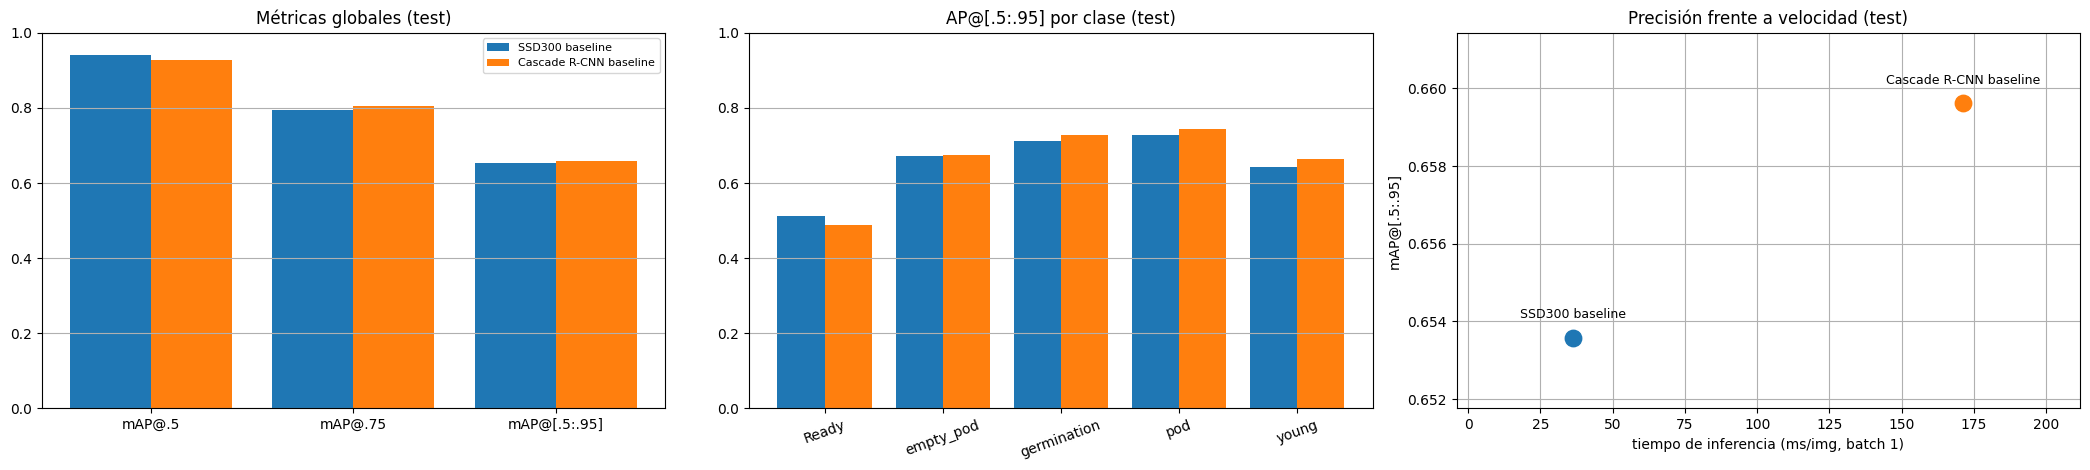

In [ ]:
test = res[res.split == "test"].set_index("exp").loc[list(EXP_TAGS)]
fig, axs = plt.subplots(1, 3, figsize=(21, 4.8))

# Métricas globales
metrics = [("mAP50", "mAP@.5"), ("mAP75", "mAP@.75"), ("mAP", "mAP@[.5:.95]")]
w = 0.8 / len(test)
for i, (exp, r) in enumerate(test.iterrows()):
    axs[0].bar(np.arange(len(metrics)) + (i - (len(test) - 1) / 2) * w, [r[m] for m, _ in metrics], w, label=exp, color=EXP_COLORS[exp])
axs[0].set_xticks(range(len(metrics))); axs[0].set_xticklabels([l for _, l in metrics])
axs[0].set_title("Métricas globales (test)")
axs[0].set_ylim(0, 1)
axs[0].grid(axis="y")
axs[0].legend(fontsize=8)

# AP por clase
x = np.arange(K)
for i, (exp, r) in enumerate(test.iterrows()):
    axs[1].bar(x + (i - (len(test) - 1) / 2) * w, [r[f"AP_{c}"] for c in CLASS_NAMES], w, label=exp, color=EXP_COLORS[exp])
axs[1].set_xticks(x)
axs[1].set_xticklabels(CLASS_NAMES, rotation=20)
axs[1].set_title("AP@[.5:.95] por clase (test)")
axs[1].set_ylim(0, 1)
axs[1].grid(axis="y")

# Precisión frente a coste
for exp, r in test.iterrows():
    axs[2].scatter(r["infer_ms_img"], r["mAP"], s=140, color=EXP_COLORS[exp], zorder=3)
    axs[2].annotate(exp, (r["infer_ms_img"], r["mAP"]), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=9)
axs[2].set_xlabel("tiempo de inferencia (ms/img, batch 1)")
axs[2].set_ylabel("mAP@[.5:.95]")
axs[2].set_title("Precisión frente a velocidad (test)")
axs[2].grid(True)
axs[2].margins(x=0.3, y=0.3)

plt.tight_layout()
plt.savefig(WORK_DIR / "figs" / "baseline_comparison.png", dpi=130)
plt.show()

Las gráficas permiten comparar el comportamiento de ambos detectores desde tres perspectivas complementarias. En primer lugar, las métricas globales muestran que el rendimiento de SSD300 y Cascade R-CNN es muy similar. En segundo lugar, el análisis por clases permite identificar aquellas categorías en las que cada modelo presenta mayores dificultades. Por último, la relación entre precisión y velocidad pone de manifiesto las diferencias de eficiencia entre ambas arquitecturas.

La gráfica de métricas globales confirma que ambos detectores presentan un rendimiento muy parecido, con diferencias prácticamente inapreciables en mAP@[.5:.95].

Al observar el AP por clase, `Ready` destaca como la categoría más problemática para ambos modelos, con valores de 0,512 para SSD300 y 0,489 para Cascade R-CNN. El resto de categorías obtienen resultados superiores, entre 0,64 y 0,74. Aunque Cascade R-CNN presenta pequeñas ventajas en ellas, estas diferencias no son suficientes para establecer una superioridad general.

Resulta especialmente interesante que `Ready` sea la clase con objetos de mayor tamaño, con una mediana de 187 píxeles. Por tanto, sus dificultades no parecen estar relacionadas directamente con el tamaño reducido de los objetos ni con una menor disponibilidad de ejemplos, sino que podrían deberse a la complejidad de delimitar correctamente plantas grandes y frondosas.

Finalmente, la gráfica de precisión frente a velocidad muestra claramente la diferencia de eficiencia entre los modelos. Aunque Cascade R-CNN consigue una mejora muy pequeña en mAP, necesita considerablemente más tiempo de inferencia (36,4ms vs 171,3ms). Además, el eje vertical está recortado, por lo que amplifica visualmente una diferencia que en realidad es mínima. Desde el punto de vista de la relación entre rendimiento y coste computacional, SSD300 resulta la alternativa más eficiente.

En conjunto, los resultados muestran que Cascade R-CNN obtiene una ligera ventaja en algunas métricas de precisión, pero esta mejora es muy reducida en comparación con el mayor coste computacional que implica su utilización.

### Curvas precisión-recall

Las curvas precisión-recall de cada clase nos permiten ver cómo se comporta cada detector al variar el umbral de confianza. Las dibujamos con dos *umbrales de IoU*: `0,5`, que responde a si el detector encuentra el objeto, y `0,75`, que exige además localizarlo con precisión. La distancia entre las dos filas indica cuánto depende cada clase de la calidad de la caja, y la comparación entre columnas, qué detector se degrada menos al endurecer el criterio.

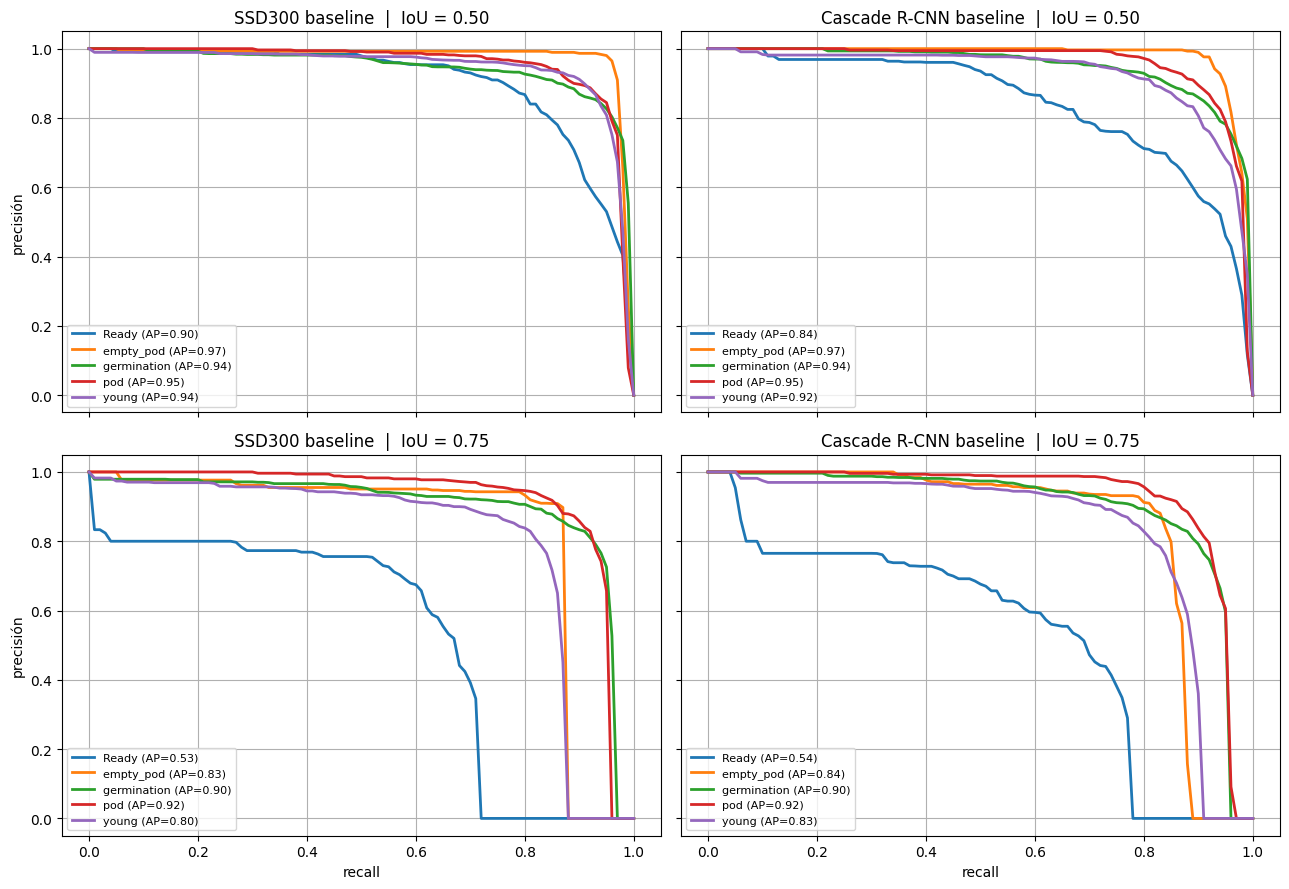

In [ ]:
def load_preds(tag, split):
    return json.loads((WORK_DIR / "preds" / f"{tag}_{split}.json").read_text())

fig, axs = plt.subplots(2, len(EXP_TAGS), figsize=(6.5 * len(EXP_TAGS), 9), sharex=True, sharey=True, squeeze=False)
for col, (exp, tag) in enumerate(EXP_TAGS.items()):
    ev = run_cocoeval(COCO_GT["test"], load_preds(tag, "test"))
    for row, thr in enumerate((0.50, 0.75)):
        t = int(np.argmin(np.abs(ev.params.iouThrs - thr)))
        ax = axs[row, col]
        for k, cname in enumerate(CLASS_NAMES):
            p = ev.eval["precision"][t, :, k, 0, 2] # precisión en los 101 niveles de recall
            ax.plot(ev.params.recThrs, p, color=CLASS_COLORS[k], lw=2, label=f"{cname} (AP={_mean_valid(p):.2f})")
        ax.set_title(f"{exp}  |  IoU = {thr:.2f}"); ax.grid(True); ax.legend(fontsize=8, loc="lower left")
        if row == 1: ax.set_xlabel("recall")
        if col == 0: ax.set_ylabel("precisión")
plt.tight_layout()
plt.savefig(WORK_DIR / "figs" / "baseline_pr_curves.png", dpi=130)
plt.show()

Con un umbral de IoU = 0,5, SSD300 obtiene mejores resultados en la clase `Ready`, con un AP de 0,90 frente al 0,84 de Cascade R-CNN. También presenta una ligera ventaja en `young` (0,94 frente a 0,92). En las demás categorías, ambos modelos muestran un comportamiento muy similar, con valores de AP comprendidos entre 0,94 y 0,97.

Sin embargo, al aumentar el umbral a `IoU = 0,75`, las diferencias en la calidad de las cajas se hacen más evidentes. La clase `Ready` experimenta una caída considerable de rendimiento en ambos modelos (de 0,90 a 0,53 en SSD y de 0,84 a 0,54 en Cascade), mientras que el resto de categorías presenta descensos mucho más moderados (0,03-0,14).

Este comportamiento indica que los detectores son capaces de identificar las plantas, pero tienen dificultades para ajustar sus cajas delimitadoras con suficiente precisión. En este caso, Cascade R-CNN consigue mantener un recall máximo ligeramente superior en algunas categorías, incluida `Ready`, lo que sugiere cierta ventaja en la recuperación de objetos, aunque no resuelve completamente el problema de localización.

Además, la caída de precisión de `Ready` aparece incluso con niveles de recall muy bajos. Vemos que las primeras detecciones de `Ready` con mayor confianza ya fallan, lo que apunta a dificultades sistemáticas en el ajuste de las cajas y no únicamente a errores aislados.

Estos resultados respaldan nuestra hipótesis inicial: las plantas grandes y frondosas presentan una mayor ambigüedad a la hora de determinar sus límites, lo que dificulta su localización precisa. Por tanto, el principal problema de esta categoría no parece ser tanto su detección como la delimitación correcta de cada instancia. A esto se le suma la confusión entre `Ready` y `young`, que analizaremos a continuación.

### Análisis de fallos

Para analizar los errores en un punto de operación concreto fijamos un *umbral de confianza de 0,5* y emparejamos cada detección con un objeto real cuando su IoU es al menos 0,5, sin tener en cuenta la clase. Cada celda de la matriz cuenta con qué clase se ha detectado cada objeto real. La última columna recoge los objetos no detectados y la última fila las detecciones que no corresponden a ningún objeto real (falsos positivos). Así, distinguimos entre confusiones entre clases, objetos que se escapan y detecciones sobrantes, que requieren estrategias de mejora distintas.

,objetos reales,detecciones,aciertos,recall,precisión,clase confundida,no detectados,falsos positivos
exp,,,,,,,,
SSD300 baseline,3866,3924,3432,0.888,0.875,237,197,255
Cascade R-CNN baseline,3866,4059,3410,0.882,0.840,297,159,352


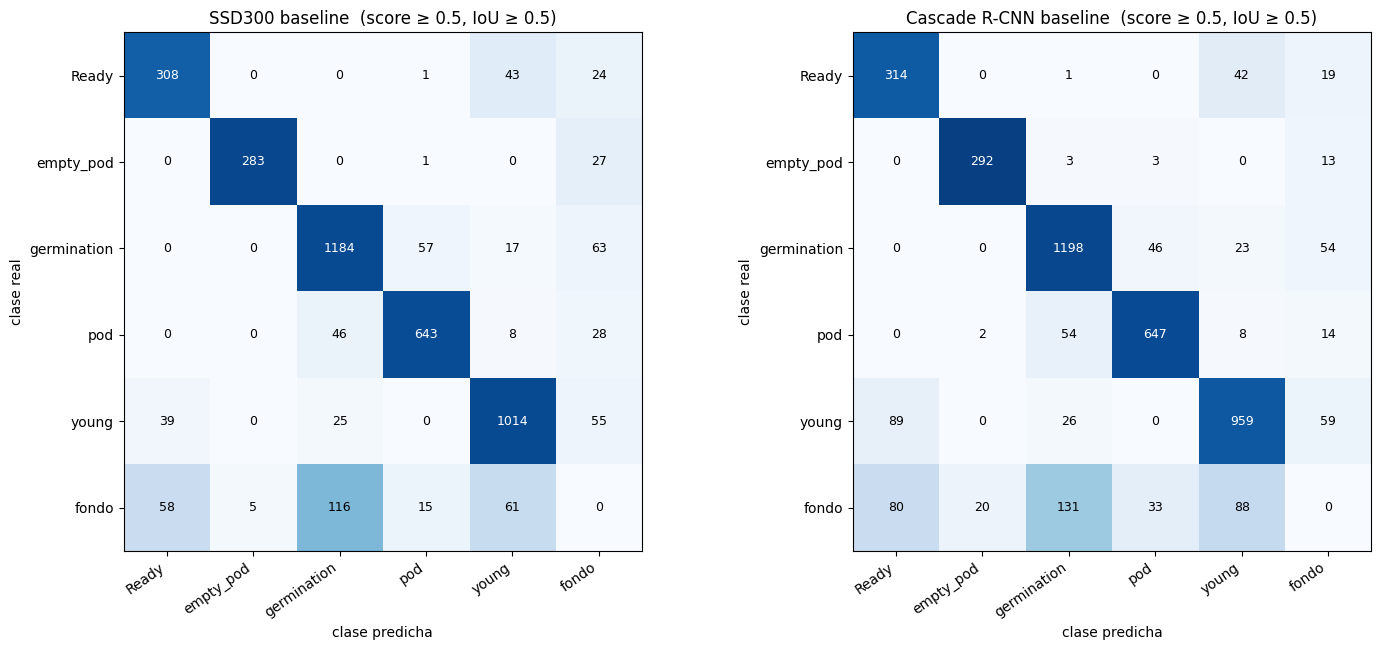

In [ ]:
SCORE_VIS = 0.5 # umbral de confianza del punto de operación para el análisis de fallos
IOU_MATCH = 0.5 # umbral de IoU para considerar que una detección coincide con un objeto real (para la matriz de confusión)

def group_by_image(preds, score_thr=SCORE_VIS):
    """Predicciones con score >= umbral, agrupadas por imagen y ordenadas de mayor a menor confianza."""
    g = defaultdict(list)
    for p in preds:
        if p["score"] >= score_thr: g[p["image_id"]].append(p)
    for v in g.values(): v.sort(key=lambda p: -p["score"])
    return g

def box_iou_xywh(a, b):
    """IoU entre dos conjuntos de cajas [x, y, w, h] -> matriz (len(a), len(b))."""
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, 0][:, None], b[:, 0][None]), 0, None) # ancho de intersección
    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, 1][:, None], b[:, 1][None]), 0, None) # alto de intersección
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter
    return inter / np.maximum(union, 1e-9)

def detection_confusion(coco_gt, by_img, image_ids=None, iou_thr=IOU_MATCH):
    """Matriz de confusión de detección: filas = clase real, columnas = clase predicha, y una fila/columna extra de 'fondo'.
    Cada detección (de mayor a menor confianza) se empareja con el objeto real libre de mayor IoU (>= iou_thr), sin mirar la clase.
    Un objeto real sin detección cuenta en la columna 'fondo' (no detectado) y una detección sin objeto real, en la fila 'fondo'."""
    n = len(CLASS_NAMES)
    cm = np.zeros((n + 1, n + 1), dtype=int)
    for iid in (image_ids if image_ids is not None else coco_gt.imgs):
        gts = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=iid)); dts = by_img.get(iid, []) # detecciones ordenadas por score
        gt_cls = [CID2IDX[g["category_id"]] for g in gts] # clase real de cada objeto
        
        # Calculamos la matriz de IoU entre detecciones y objetos reales
        iou = box_iou_xywh(np.array([d["bbox"] for d in dts]).reshape(-1, 4),
                           np.array([g["bbox"] for g in gts]).reshape(-1, 4)) if dts and gts else None
        
        used = set() # índices de objetos reales ya emparejados
        
        # Emparejamos cada detección con el objeto real libre de mayor IoU (>= iou_thr)
        for i, d in enumerate(dts):
            j = -1
            if iou is not None:
                free = [g for g in range(len(gts)) if g not in used and iou[i, g] >= iou_thr]
                if free: j = max(free, key=lambda g: iou[i, g])
            if j >= 0:
                used.add(j); cm[gt_cls[j], CID2IDX[d["category_id"]]] += 1
            else:
                cm[n, CID2IDX[d["category_id"]]] += 1
        for g in range(len(gts)):
            if g not in used: cm[gt_cls[g], n] += 1
    return cm

# Creamos una matriz de confusión de detección para cada experimento
cms, rows = {}, []
for exp, tag in EXP_TAGS.items():
    cms[exp] = detection_confusion(COCO_GT["test"], group_by_image(load_preds(tag, "test")))
    cm = cms[exp]; tp = int(np.trace(cm[:K, :K]))
    rows.append({"exp": exp, "objetos reales": int(cm[:K].sum()), "detecciones": int(cm[:, :K].sum()), "aciertos": tp,
                 "recall": tp / cm[:K].sum(), "precisión": tp / cm[:, :K].sum(),
                 "clase confundida": int(cm[:K, :K].sum() - tp), "no detectados": int(cm[:K, K].sum()), "falsos positivos": int(cm[K, :K].sum())})
display(pd.DataFrame(rows).set_index("exp").round(3))

fig, axs = plt.subplots(1, len(cms), figsize=(7.4 * len(cms), 6.6), squeeze=False)
labels = CLASS_NAMES + ["fondo"]
for ax, (exp, cm) in zip(axs[0], cms.items()):
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) # cada fila suma 1, representando la proporción de qué clase se detecta cada clase real
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K + 1):
        for j in range(K + 1):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels)
    ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real"); ax.set_title(f"{exp}  (score ≥ {SCORE_VIS}, IoU ≥ {IOU_MATCH})")
plt.tight_layout(); plt.savefig(WORK_DIR / "figs" / "baseline_confusion.png", dpi=130); plt.show()

Los resultados de la matriz de confusión permiten identificar diferencias importantes en el comportamiento de ambos detectores. Aunque Cascade R-CNN consigue recuperar más objetos reales, también genera un mayor número de falsos positivos y confusiones entre categorías. En concreto, detecta menos objetos sin recuperar (159 frente a 197 de SSD300), pero produce 97 falsos positivos adicionales y 60 confusiones de clase más. Por tanto, con un umbral de confianza de 0,5, SSD300 presenta un comportamiento más equilibrado en este punto de operación.

La confusión más destacada se produce entre las categorías `Ready` y `young`. Ambos modelos tienen dificultades para distinguir estos estadios de crecimiento por ser bastante parecidos (plantas grandes), pero el problema es especialmente acusado en Cascade R-CNN, que clasifica 89 lechugas `young` como `Ready` (y 42 `Ready` como `young`), frente a las 39 (y 43 `Ready` como `young`) de SSD300. Esta diferencia ayuda a explicar el peor rendimiento (AP50) de Cascade R-CNN en la clase `Ready` observado anteriormente.

También aparece una confusión recurrente entre `germination` y `pod`, con aproximadamente un centenar de casos en ambos modelos (57 + 46 en SSD, 46 + 54 en Cascade). Por el contrario, `empty_pod` presenta un comportamiento muy bueno, con 283 y 292 aciertos respectivamente y muy pocos errores de clasificación.

En cuanto a los falsos positivos, estes se concentran principalmente en las categorías `germination` (116 en SSD y 131 en Cascade), `young` (61 en SSD y 88 en Cascade) y `Ready` (58 en SSD y 80 en Cascade). Este patrón se repite en ambos detectores, lo que sugiere que las dificultades no dependen exclusivamente de la arquitectura utilizada, sino que también pueden estar relacionadas con las características de los datos y las anotaciones del conjunto.

En definitiva, los resultados refuerzan la idea de que los principales problemas se encuentran en la distinción entre estadios de crecimiento similares y en la identificación de los límites de las plantas.

### Ejemplos cualitativos

Por último, vamos a comparar las detecciones sobre las mismas imágenes de *test*: dos elegidas al azar con semilla fija, como ejemplos representativos del comportamiento habitual, y las dos en las que ambos detectores suman más errores, que son los casos difíciles.

Cada fila muestra el ground truth y las detecciones de cada detector con puntuación mayor o igual que 0,5, con el número de errores (confusiones, objetos no detectados y falsos positivos) en el título.

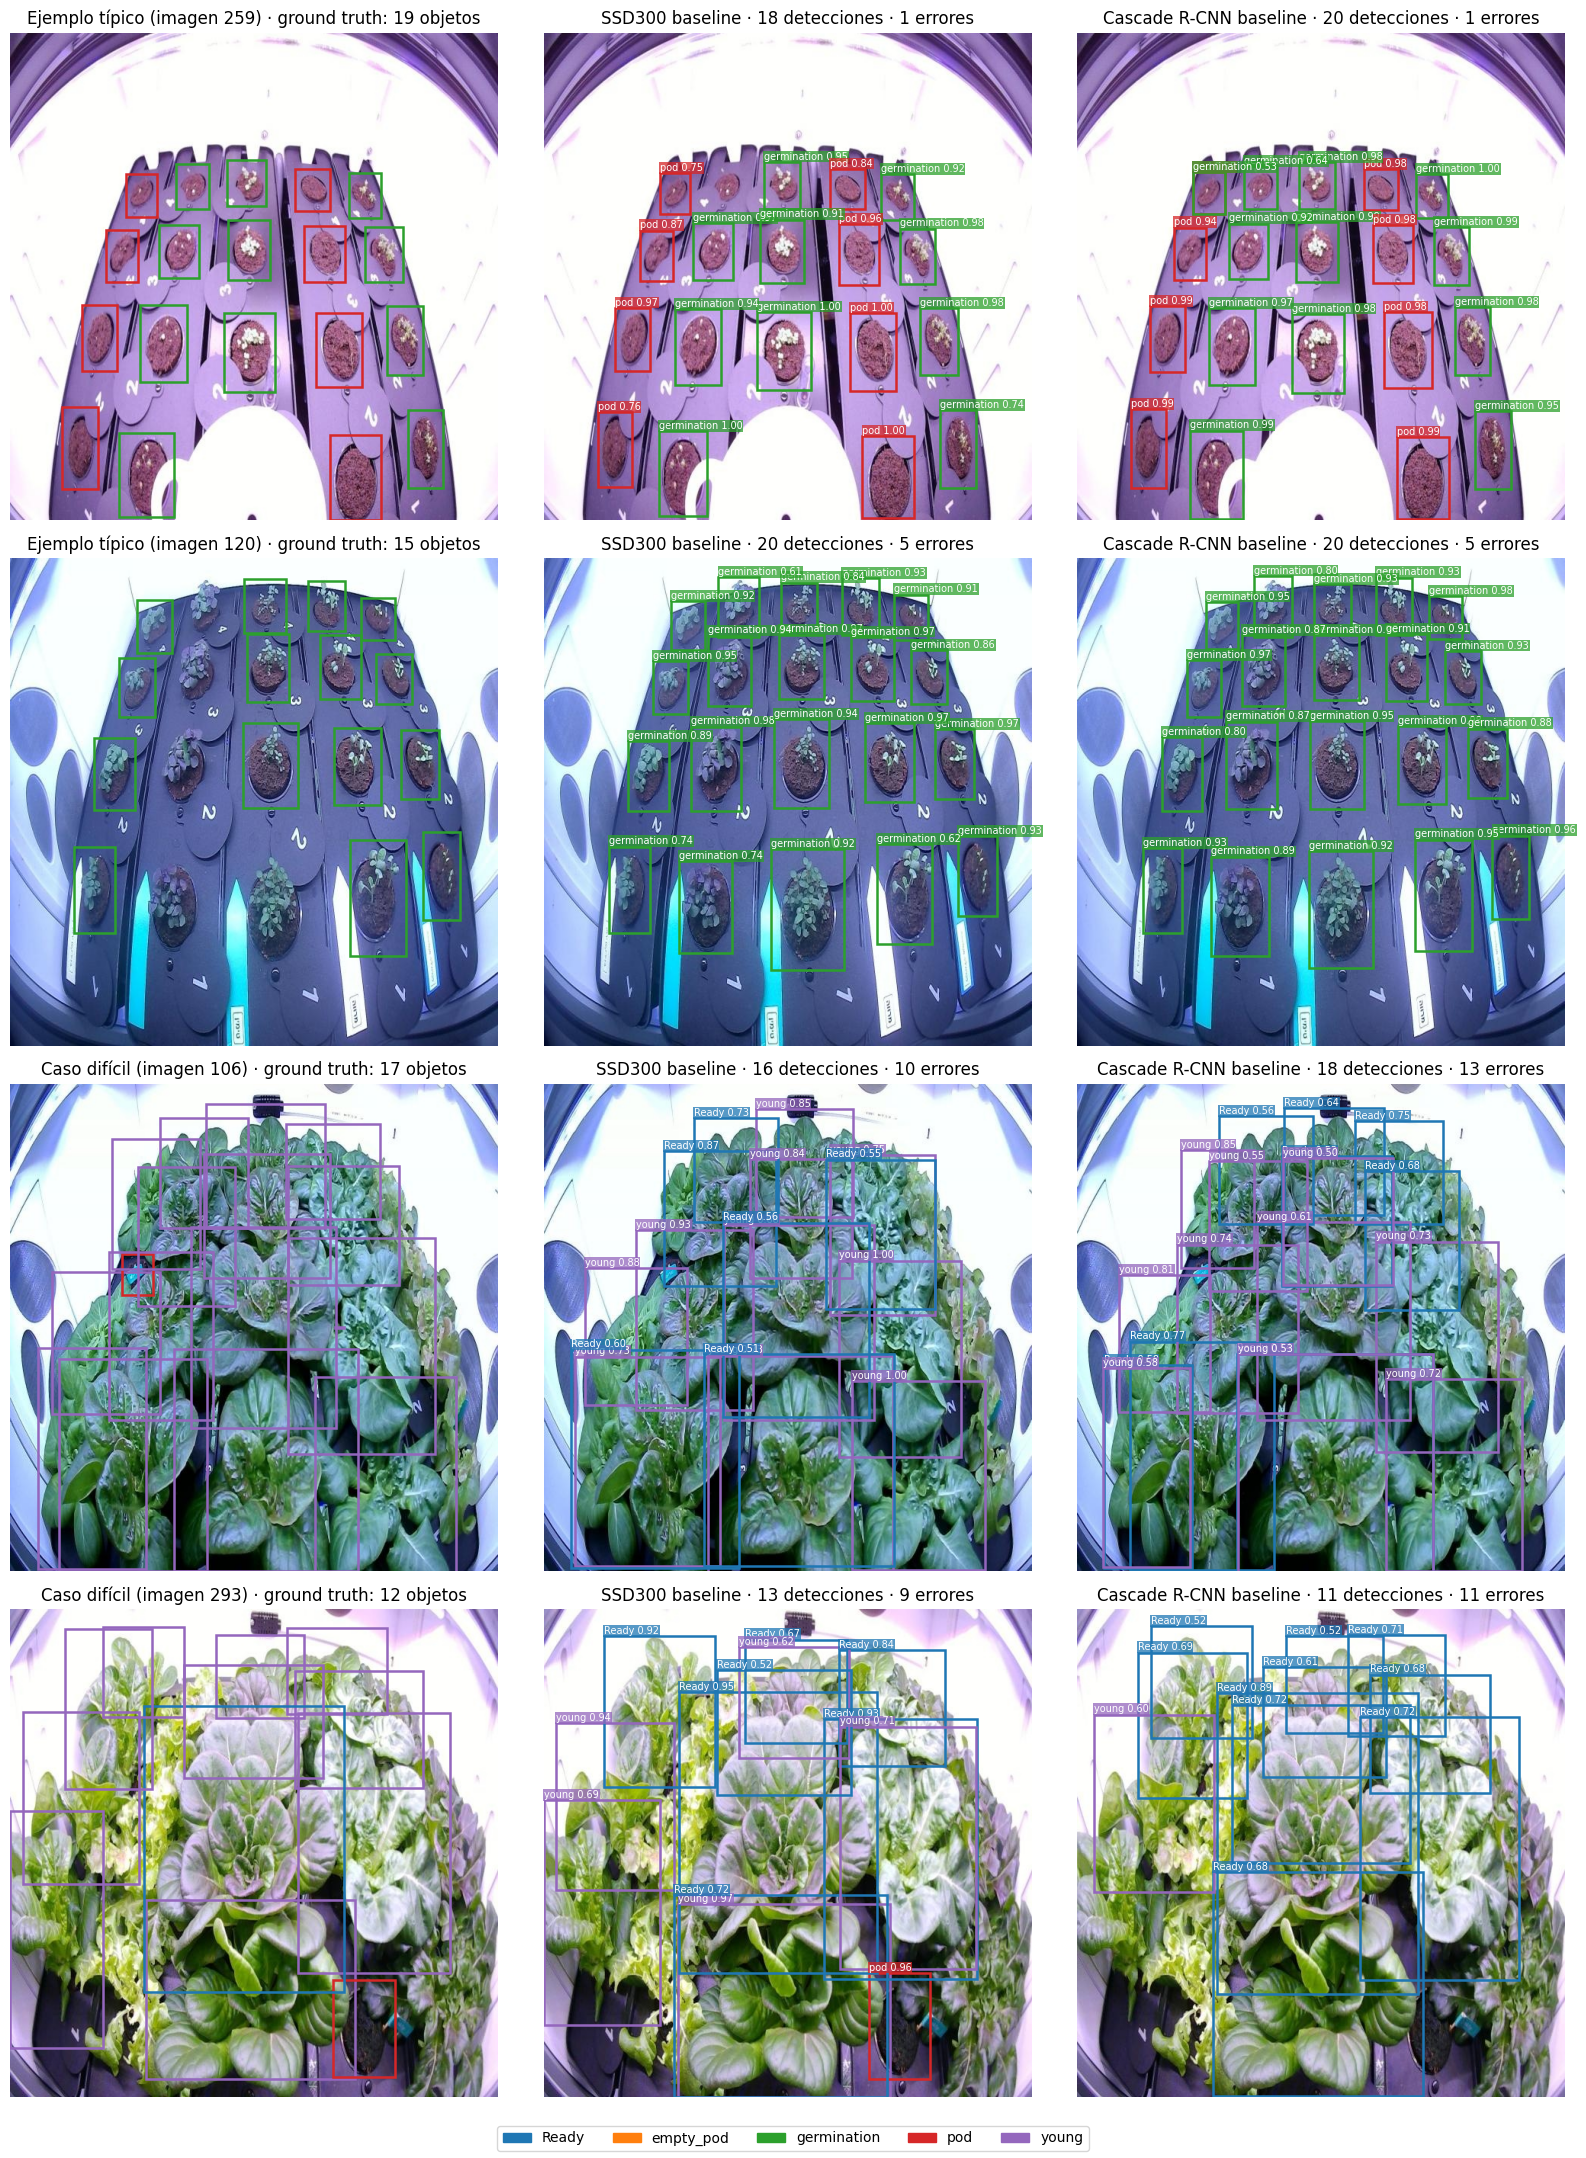

In [ ]:
# Dibujamos las cajas de los objetos reales y las detecciones en la misma imagen, con colores distintos para cada clase
def draw_boxes(ax, boxes, cids, scores=None):
    for i, (x, y, w, h) in enumerate(boxes):
        c = CLASS_COLORS[CID2IDX[cids[i]]]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=1.8, ec=c))
        if scores is not None:
            ax.text(x, max(y - 3, 8), f"{CLASS_NAMES[CID2IDX[cids[i]]]} {scores[i]:.2f}", fontsize=7, color="white",
                    bbox=dict(facecolor=c, alpha=0.75, pad=0.6, lw=0))

# Mostramos algunos ejemplos de imágenes con sus objetos reales y las detecciones de cada experimento, indicando el número de errores
coco_t = COCO_GT["test"]
grouped = {exp: group_by_image(load_preds(tag, "test")) for exp, tag in EXP_TAGS.items()}

# Contamos el número de errores de detección en una imagen concreta y un experimento concreto
def n_errors(exp, iid):
    cm = detection_confusion(coco_t, grouped[exp], [iid])
    return int(cm.sum() - np.trace(cm[:K, :K])) # confundidas + no detectadas + falsos positivos

# Mostramos 2 ejemplos típicos y 2 casos difíciles de la prueba
total_err = {iid: sum(n_errors(exp, iid) for exp in EXP_TAGS) for iid in coco_t.imgs}
rng = random.Random(SEED)
typical = rng.sample(sorted(coco_t.imgs), 2)
hard = [i for i in sorted(total_err, key=total_err.get, reverse=True) if i not in typical][:2]
cases = [("Ejemplo típico", i) for i in typical] + [("Caso difícil", i) for i in hard]

# Dibujamos las imágenes con sus objetos reales y las detecciones de cada experimento
ncol = 1 + len(EXP_TAGS)
fig, axs = plt.subplots(len(cases), ncol, figsize=(5.4 * ncol, 5.4 * len(cases)))
for r, (kind, iid) in enumerate(cases):
    info = coco_t.imgs[iid]; img = Image.open(CLEAN["test"]["images"] / info["file_name"]).convert("RGB")
    anns = coco_t.loadAnns(coco_t.getAnnIds(imgIds=iid))
    axs[r, 0].imshow(img); draw_boxes(axs[r, 0], [a["bbox"] for a in anns], [a["category_id"] for a in anns])
    axs[r, 0].set_title(f"{kind} (imagen {iid}) · ground truth: {len(anns)} objetos")
    for c, exp in enumerate(EXP_TAGS, start=1):
        dts = grouped[exp].get(iid, [])
        axs[r, c].imshow(img)
        draw_boxes(axs[r, c], [d["bbox"] for d in dts], [d["category_id"] for d in dts], [d["score"] for d in dts])
        axs[r, c].set_title(f"{exp} · {len(dts)} detecciones · {n_errors(exp, iid)} errores")
    for ax in axs[r]: ax.axis("off")
handles = [patches.Patch(color=CLASS_COLORS[i], label=n) for i, n in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, loc="lower center", ncol=K)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig(WORK_DIR / "figs" / "baseline_qualitative.png", dpi=110)
plt.show()

Estos ejemplos visuales nos permiten comprobar cómo se manifiestan los errores identificados en el análisis cuantitativo.

Vemos que en la imagen 259, seleccionada como ejemplo representativo, ambos modelos obtienen buenos resultados: de los 19 objetos reales, cada detector comete únicamente un error. Se trata de una escena en la que las macetas aparecen separadas y bien iluminadas, lo que facilita tanto su detección como su localización.

En la imagen 120, también típica, ambos modelos cometen cinco errores, coincidiendo además en ellos. En concreto, identifican como `germination` algunas plantas del centro de la bandeja que no aparecen anotadas en el ground truth. Esto podría indicar que las anotaciones están incompletas y que algunas detecciones contabilizadas como falsos positivos se corresponderían realmente a objetos existentes. No obstante, se trata de una hipótesis basada en un único ejemplo visual, tendríamos que revisar más imágenes para confirmarla.

En cuanto a los casos difíciles, tenemos a las imágenes 106 y 293 para representarlas. En ellas, las plantas ocupan gran parte de la imagen, presentando hojas solapadas y generando cajas delimitadoras de gran tamaño que incluso se cruzan entre sí. En estas condiciones, ambos modelos tienen dificultades para distinguir correctamente las categorías `Ready` y `young`, acumulando entre 9 y 13 errores por imagen. En la imagen 293 destaca especialmente el comportamiento de Cascade R-CNN, que clasifica prácticamente todas las plantas como `Ready`, algo coherente con la confusión `young` → `Ready` observada en la matriz de confusión. Por otro lado, SSD300 consigue detectar correctamente una maceta de la categoría `pod`, situada en la parte inferior derecha, con una confianza de 0,96, mientras que Cascade R-CNN no consigue identificarla.

En conjunto, los ejemplos confirman que los errores se concentran principalmente en escenas complejas, con plantas de estadios avanzados que presentan solapamientos y límites difíciles de distinguir. Por el contrario, las categorías correspondientes a etapas tempranas y los objetos visualmente separados suelen detectarse con mucha mayor facilidad.

#### Conclusiones de la comparación

La comparación entre SSD300 y Cascade R-CNN muestra que ambos detectores alcanzan un rendimiento muy similar, sin que exista una superioridad clara y consistente de una arquitectura sobre la otra. Aunque Cascade R-CNN presenta pequeñas ventajas en algunas métricas, estas diferencias son reducidas y debemos interpretarlas con cautela, teniendo en cuenta que se ha realizado un único entrenamiento por modelo y que el conjunto de test es relativamente pequeño, con 299 imágenes.

En cambio, las diferencias de coste computacional son mucho más evidentes. SSD300 requiere considerablemente menos tiempo de inferencia (36,4ms vs 171,3ms) y entrenamiento (20,3ms vs 62,8ms), además de utilizar un menor número de parámetros (24,3M vs 69,1M). Por tanto, constituye una alternativa más eficiente cuando se busca un equilibrio entre precisión y velocidad.

El análisis por categorías permite identificar `Ready` como la principal fuente de errores. A pesar de tratarse de la clase con objetos de mayor tamaño y de no ser la menos frecuente, presenta el AP más bajo en ambos detectores: cuenta con un AP@[.5:.95] en torno a 0,5, mientras que el resto de clases superan el 0,63. Las curvas precisión-recall y la matriz de confusión apuntan a dos problemas principales: la dificultad para ajustar correctamente las cajas delimitadoras de plantas grandes y frondosas y la confusión entre los estadios `Ready` y `young`.

Los ejemplos cualitativos refuerzan estas conclusiones y muestran que los errores aumentan en escenas con plantas solapadas y límites poco definidos. Asimismo, existe la posibilidad de que algunas anotaciones incompletas estén afectando a la evaluación, aunque sería necesario realizar una revisión más amplia para confirmarlo.